# 16 — Clustering SBERT passo per passo (versione didattica)

Questo notebook segue **una sola riga** di Multi-News (un cluster di 2-3 articoli + il riassunto
umano di riferimento) e mostra, un passaggio alla volta, come il **clustering su sentence embedding**
(la ricetta di `bert-extractive-summarizer`, Miller 2019) trasforma il testo in un riassunto estrattivo
e come lo si valuta.

A differenza di [`notebooks/16_sbert_clustering.ipynb`](../notebooks/16_sbert_clustering.ipynb), che gira
in batch su migliaia di righe e salva solo i risultati, qui l'obiettivo è **capire**: ogni passaggio è
spiegato, calcolato "a mano" quando possibile (il coseno, le iterazioni di K-means, le fusioni del
clustering agglomerativo, centroidi e medoidi, l'ordine a giri) e **verificato contro l'implementazione
del benchmark** (le `assert` garantiscono che quello che vedi qui sia esattamente ciò che fa il codice
di produzione).

## Il workflow in una figura

```
documento (2-3 articoli)
      │  1. scelta della riga
      ▼
frasi  s₀ s₁ … s_{N-1}              ← 2. suddivisione in frasi
      │
      ▼
embedding SBERT  eᵢ ∈ ℝ³⁸⁴, ‖eᵢ‖ = 1  ← 3. vettori densi: vicini = stesso significato
      │
      ├──► 4. K-means       (sbert_kmeans)  ┐ unica differenza
      ├──► 5. agglomerativo (sbert_agglom)  ┘ tra le due varianti
      ▼
k gruppi (sottotemi)
      │
      ▼
centroide e medoide di ogni gruppo     ← 6. una frase per gruppo: la più vicina al centroide
      │
      ▼
ordine di selezione                    ← 7. 'frasi': i medoidi | 'budget': a giri, gruppi grandi prima
      │
      ▼
riassunto estrattivo                   ← 8-9. selezione + generazione (frasi in ordine di documento)
      │
      ▼
confronto con il riferimento           ← 10. + variante a budget di parole
      │
      ▼
ROUGE / BLEU / METEOR                  ← 11. metriche
      │
      ▼
interpretazione                        ← 12-13.
```

## L'idea in tre mosse
1. ogni frase diventa un **vettore denso** calcolato da un encoder pre-addestrato (**SBERT**,
   `all-MiniLM-L6-v2`): vettori vicini = **significato** vicino, *anche senza parole in comune*;
2. l'insieme delle frasi si **partiziona** in `k` gruppi omogenei (*clustering*), uno per sottotema;
3. da ogni gruppo si estrae **una** frase, quella più vicina al centroide del gruppo (il **medoide**).

Siccome i gruppi sono una **partizione**, il riassunto tocca tutti i sottotemi trovati e non può
contenere due frasi quasi uguali (sarebbero finite nello stesso gruppo): l'**anti-ridondanza** non è un
termine da tarare, come il `λ` dell'MMR ([`11`](11_centroid_mmr_didattico.ipynb)), ma una conseguenza
della struttura. Il benchmark ne genera **due varianti**, identiche tranne che per l'algoritmo di
clustering:

- **`sbert_kmeans`** — **K-means**: minimizza la distanza (euclidea) dai centroidi;
- **`sbert_agglom`** — **agglomerativo** con distanza coseno e *average linkage*: fonde a ogni passo i due
  gruppi più simili.

> Come Centroid+MMR ([`11`](11_centroid_mmr_didattico.ipynb)) e LSA ([`15`](15_lsa_didattico.ipynb)) qui non
> c'è grafo né PageRank. Gli embedding sono gli stessi di TextRank ([`01`](01_textrank_didattico.ipynb)) e della
> variante BERT di Centroid+MMR. I passi 1-2 e 10-12 sono identici agli altri notebook didattici.

⚠️ **Una riga non è un benchmark.** Le metriche della sezione 11 riguardano un solo esempio e
servono a capire *come si calcolano*, non a stabilire quale metodo sia migliore (per questo
esistono i notebook di benchmark su 5.610 righe).

## 0. Preparazione
Importiamo le librerie e le funzioni condivise del progetto (`summ_utils`). Il notebook si può
lanciare dalla cartella `notebooks_didattici/` o dalla radice del repository. Alla prima esecuzione
scarica l'encoder `all-MiniLM-L6-v2` (~90 MB); per una sola riga basta la CPU.

In [1]:
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# radice del progetto: la cartella sopra notebooks_didattici/ (o la cwd se già alla radice)
_cwd = Path.cwd()
BASE = _cwd.parent if _cwd.name in ('notebooks_didattici', 'notebooks') else _cwd
sys.path.insert(0, str(BASE / 'notebooks'))

import summ_utils as su
from pyAutoSummarizer.base import psr

su.stile_grafici()
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 110

P = su.percorsi_standard(BASE)
DEVICE = su.rileva_device()
print('Radice del progetto:', BASE, '| device:', DEVICE)

C:\Users\maccu\AppData\Roaming\Python\Python312\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.7) doesn't match a supported version!
  warnings.warn(


C:\Users\maccu\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Radice del progetto: C:\Users\maccu\OneDrive\Desktop\Master_Project | device: cpu


## 1. Selezione del testo di partenza
Multi-News è composto da *cluster*: ogni riga contiene **2-3 articoli** sullo stesso evento,
concatenati con il separatore `|||||`, e un **riassunto scritto da un umano** (il
*riferimento*, o *gold*). Lavoriamo sulla **split di test** (la stessa su cui il benchmark
valuta i metodi).

`ROW_ID` è l'indice globale della riga in `data/tab/complete.tab`. La riga predefinita
(**50492**) è la stessa degli altri notebook didattici: è breve (19 frasi), quindi matrici e grafici
restano **leggibili**. Per questo metodo è però un caso **estremo**: 11 gruppi su 19 frasi sono quasi una
frase per gruppo, e molti gruppi saranno *singoletti*. È un difetto utile da vedere (sezioni 4-6); su una
riga tipica del test (mediana ~50 frasi) i gruppi sono più popolati — vedi gli esercizi.

**`MODALITA`** sceglie come viene fissata la **lunghezza** del riassunto. Il metodo produce un
*ordine* delle frasi (i medoidi, poi i rappresentanti successivi dei gruppi): quante frasi prenderne è una
scelta esterna.

| `MODALITA` | regola | corrisponde a |
|---|---|---|
| `'frasi'` | gli `N_CLUSTER` (= 11) medoidi, uno per gruppo | ambito `test` del benchmark |
| `'budget'` | frasi nell'ordine a giri finché si raggiunge la lunghezza in parole del riferimento, poi tetto a 1,25× | ambito `test_budgetref` (issue #16) |

Cambiando `MODALITA` le sezioni 8-12 si adattano; le due alternative restano comunque
confrontabili nelle tabelle delle sezioni 10 e 11.

**`VARIANTE`** sceglie l'algoritmo di clustering: `'sbert_kmeans'` (default) oppure `'sbert_agglom'`. Le
sezioni 4 e 5 li mostrano entrambi, la 13 li confronta sulla stessa riga. `N_CLUSTER` vale 11 anche
nell'ambito a budget: è un parametro **strutturale** (quanti sottotemi cercare), non di lunghezza.

In [2]:
ROW_ID = 50492          # riga della split di test (50491-56100)
# Come si decide la LUNGHEZZA del riassunto (il metodo produce solo un ordine delle frasi):
#   'frasi'  -> gli N_CLUSTER medoidi, uno per gruppo (benchmark ambito `test`)
#   'budget' -> frasi nell'ordine a giri fino alla lunghezza in parole del riferimento,
#               poi tetto a 1,25x (benchmark ambito `test_budgetref`, issue #16)
MODALITA = 'budget'
N_SENTENCES = 11                  # frasi del riassunto in modalità 'frasi' (mediana del corpus)
N_CLUSTER = N_SENTENCES           # una frase per gruppo: k = budget di frasi (come il benchmark)
VARIANTE = 'sbert_kmeans'         # 'sbert_kmeans' (K-means) | 'sbert_agglom' (agglomerativo, coseno)
ST_MODEL = 'all-MiniLM-L6-v2'     # stesso encoder di TextRank e di centroid_mmr_bert
SEED = 42                         # random_state di KMeans (come il benchmark)
assert MODALITA in ('frasi', 'budget'), "MODALITA deve essere 'frasi' oppure 'budget'"
assert VARIANTE in ('sbert_kmeans', 'sbert_agglom'), "VARIANTE deve essere 'sbert_kmeans' oppure 'sbert_agglom'"

import csv

PRIMO_ROW_ID_TEST = 50491          # le righe di test sono 50491-56100 in complete.tab
PERCORSO_TEST = P['complete_tab'].with_name('test.tab')   # solo split test (68 MB): basta e avanza

def carica_riga_test(row_id):
    """Legge UNA riga di test. Prima da data/tab/test.tab (leggero, ideale su Colab: row_id = 50491 + indice,
    allineamento verificato con complete.tab), altrimenti da complete.tab (690 MB)."""
    problemi = []
    if PERCORSO_TEST.exists():
        try:
            with open(PERCORSO_TEST, encoding='utf-8', newline='') as f:
                lettore = csv.reader(f, delimiter='\t')
                for _ in range(su.HEADER_LINES_TAB):
                    next(lettore)
                for i, riga in enumerate(lettore):
                    if i == row_id - PRIMO_ROW_ID_TEST:
                        documento, riassunto_umano = riga          # ValueError se la riga è corrotta
                        return {'row_id': row_id, 'split': 'test', 'document': documento, 'summary': riassunto_umano}
            problemi.append(f'{PERCORSO_TEST.name}: row_id {row_id} fuori dalla split di test (50491-56100)')
        except ValueError:
            problemi.append(f'{PERCORSO_TEST.name} è incompleto o corrotto (riga con un numero di colonne inatteso)')
    else:
        problemi.append(f'{PERCORSO_TEST} non trovato')
    if P['complete_tab'].exists():
        try:
            return next(es for es in su.itera_split(P['complete_tab'], 'test') if es['row_id'] == row_id)
        except (ValueError, StopIteration):
            problemi.append(f'{P["complete_tab"].name} è incompleto o corrotto')
    else:
        problemi.append(f'{P["complete_tab"]} non trovato')
    raise RuntimeError('Impossibile leggere la riga: ' + ' | '.join(problemi) + '.\n'
        'I file .tab del repository sono su Git LFS: un `git clone` senza LFS (o un upload interrotto su Colab) '
        'dà un puntatore di pochi byte o un file troncato. Soluzioni: `git lfs pull`, oppure carica '
        'data/tab/test.tab (68 MB) in <radice>/data/tab/.')

esempio = carica_riga_test(ROW_ID)

articoli = [a.strip() for a in esempio['document'].split('|||||')]
riferimento = su.pulisci_riferimento(esempio['summary'])

print(f"row_id {ROW_ID} | split: {esempio['split']} | articoli nel cluster: {len(articoli)}")
print(f"parole nel documento: {len(esempio['document'].split())} | parole nel riferimento: {len(riferimento.split())}")
for k, a in enumerate(articoli, 1):
    print(f"\n--- Articolo {k} ({len(a.split())} parole) ---")
    print(textwrap.fill(a[:500] + ' […]', 110))
print('\n=== RIASSUNTO DI RIFERIMENTO (umano) ===')
print(textwrap.fill(riferimento, 110))

row_id 50492 | split: test | articoli nel cluster: 2
parole nel documento: 664 | parole nel riferimento: 168

--- Articolo 1 (482 parole) ---
UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesperson
for gay rights overnight on Boing Boing     It’s time to clarify a few details about the controversial “Hey
Facebook what’s SO wrong with a pic of two men kissing?” story, as it now beginning to be reported in the
mainstream media, and not always correctly.     First of all, with regards to the picture:     The photo which
was used to illustrate my first post about the John Snow Kiss-In i […]

--- Articolo 2 (181 parole) ---
|| News ||     Page 1 of 1             UPDATED: A photo of two men kissing that was posted on a Facebook page
protesting a London pub’s decision to eject a same-sex couple for kissing has been removed by the social
networking site, an error, according to a rep for the company.         "The photo in question does not vi

**Cosa abbiamo visto.** Il documento è l'unione dei 2-3 articoli; il riferimento è molto più
breve ed è scritto in modo *astratto* (riformula), mentre il metodo può solo **copiare frasi intere**
dal documento: per questo è *estrattivo*.

## 2. Suddivisione del testo in frasi
L'unità di analisi è la **frase**: ogni frase è un candidato del riassunto. Passi, uguali a quelli
del benchmark (`segmenta()` del notebook 16, la **stessa** segmentazione di TextRank, LexRank,
First-k, Centroid+MMR, LSA e LDA: il pool di candidati è identico per tutti gli estrattivi):

1. il separatore `|||||` tra articoli viene sostituito da un a capo (`su.prepara_documento`),
   altrimenti resterebbe dentro le "frasi";
2. `psr.summarization(...)` spezza il testo con una **espressione regolare**: taglia dopo
   `. ! ?` seguiti da spazio, **tranne** dopo abbreviazioni (`Mr`, `Dr`, `Prof`, `St`, mesi
   abbreviati, iniziali maiuscole come in "J. Smith");
3. si tengono le frasi **originali** (`s.original`, in ordine di documento) e si scartano le stringhe vuote.

Non serve alcun pre-processing (minuscole, stopword…): l'encoder SBERT riceve la frase **così com'è**,
con la sua tokenizzazione interna.

In [3]:
documento = su.prepara_documento(esempio['document'])
s = psr.summarization(documento, stop_words=['en'])

# identico a segmenta() del notebook 16
frasi = [f.strip() for f in getattr(s, 'original', []) if f and f.strip()]
N = len(frasi)
print(f'Il documento è stato diviso in N = {N} frasi.\n')

tab_frasi = pd.DataFrame({'frase': range(N), 'parole': [len(f.split()) for f in frasi],
                          'testo': [f[:105] + ('…' if len(f) > 105 else '') for f in frasi]}).set_index('frase')
display(tab_frasi)

Il documento è stato diviso in N = 19 frasi.



,parole,testo
frase,,
0,60,"UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesper…"
1,59,"First of all, with regards to the picture: \n \n The photo which was used to illustrate my first post about…"
2,23,I am not a regular viewer so I can’t say if the man on the right is an extra or an actual character
3,33,"This picture has itself caused scandal in the UK, as it was a gay kiss that was broadcast before the wate…"
4,21,"However, since this episode aired (October 2008) Christian now has a boyfriend and a few more gay kisses …"
5,25,"In relation to the John Snow Kiss-In event, I used this particular photo because I considered it to be qu…"
6,15,The photos I had considered using before I chose that one are much more racy
7,3,Oh the irony
8,37,"Secondly, the removal of the Facebook John Snow Kiss-In event: \n \n It turns out that the Facebook event f…"


**Cosa abbiamo visto.** Le frasi hanno lunghezze molto diverse e sono numerate `0 … N-1` nell'ordine
in cui compaiono nel documento: questi numeri sono gli **indici** che useremo in tutti i
grafici. La divisione è *euristica*: titoli, didascalie o frammenti senza punto finale
possono diventare "frasi" a sé (qui *"Oh the irony"*, 3 parole). Ricordiamocene: nel clustering una frase
così strana tende a finire **in un gruppo tutto suo**.

## 3. Gli embedding SBERT: frasi come punti nello spazio del significato
SBERT (*Sentence-BERT*, Reimers & Gurevych 2019) è un encoder **pre-addestrato** che trasforma una frase
in un vettore di **384 numeri**. Non sono conteggi di parole: sono coordinate in uno spazio dove la
**posizione codifica il significato**, appreso su grandi quantità di coppie di frasi simili. Due frasi
che raccontano lo stesso fatto con parole diverse (*"the mayor resigned"* / *"city hall's leader stepped
down"*) finiscono **vicine**; per il TF-IDF sarebbero quasi ortogonali.

Il benchmark chiede vettori **normalizzati** (`normalize_embeddings=True`, `‖eᵢ‖ = 1`). Ne seguono due
identità che useremo ovunque:

> **coseno(eᵢ, eⱼ) = eᵢ · eⱼ**  (il prodotto scalare *è* il coseno)
>
> **‖eᵢ − eⱼ‖² = 2 − 2 · coseno(eᵢ, eⱼ)**  (distanza euclidea e coseno ordinano le coppie allo stesso modo)

La seconda è il motivo per cui K-means, che ragiona in distanza **euclidea**, si comporta in modo sensato
su embedding pensati per il **coseno**.

> **Nota terminologica.** SBERT è un *encoder* pre-addestrato (la famiglia "Pre-trained LM" della lezione,
> slide 23 e 30), non un modello generativo: usarlo non viola il vincolo "non-LLM" di questa parte del progetto.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2796.24it/s]

Embedding: 19 frasi × 384 dimensioni | norma: min 1.0000, max 1.0000  → tutti a 1

frasi 8 e 10: coseno = eᵢ·eⱼ / (‖eᵢ‖‖eⱼ‖) = 0.7491 = eᵢ·eⱼ  ✔
                ‖eᵢ − eⱼ‖² = 0.5019 = 2 − 2·coseno = 0.5019  ✔


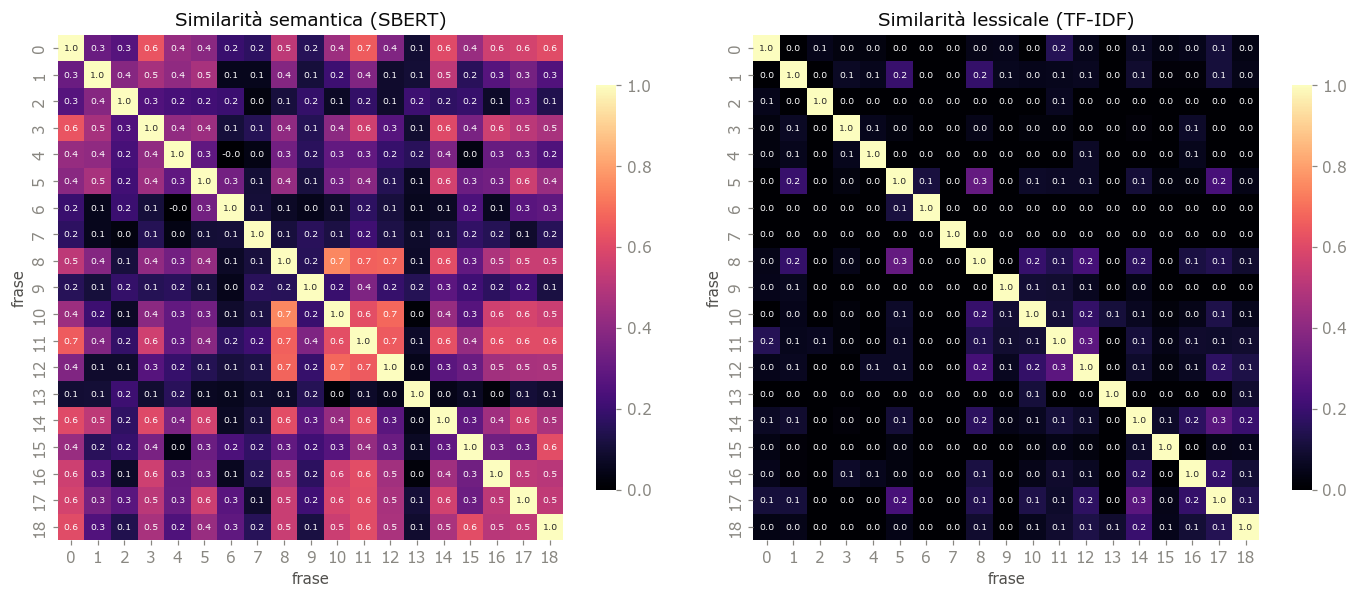

In [4]:
from sentence_transformers import SentenceTransformer

modello = SentenceTransformer(ST_MODEL, device=DEVICE)
E = modello.encode(frasi, normalize_embeddings=True, show_progress_bar=False)   # (N, 384)
print(f'Embedding: {E.shape[0]} frasi × {E.shape[1]} dimensioni | norma: min {np.linalg.norm(E, axis=1).min():.4f}, '
      f'max {np.linalg.norm(E, axis=1).max():.4f}  → tutti a 1')

# coseno a mano per una coppia, e le due identità
i, j = (8, 10) if N > 10 else (0, 1)
cos_manuale = E[i] @ E[j] / (np.linalg.norm(E[i]) * np.linalg.norm(E[j]))
assert np.isclose(cos_manuale, E[i] @ E[j], atol=1e-6)
assert np.isclose(((E[i] - E[j]) ** 2).sum(), 2 - 2 * E[i] @ E[j], atol=1e-5)
print(f'\nfrasi {i} e {j}: coseno = eᵢ·eⱼ / (‖eᵢ‖‖eⱼ‖) = {cos_manuale:.4f} = eᵢ·eⱼ  ✔')
print(f'                ‖eᵢ − eⱼ‖² = {((E[i] - E[j]) ** 2).sum():.4f} = 2 − 2·coseno = {2 - 2 * cos_manuale:.4f}  ✔')

S_sem = E @ E.T                                   # matrice dei coseni semantici
S_lex = cosine_similarity(TfidfVectorizer(stop_words='english').fit_transform(frasi))   # coseni lessicali (TF-IDF)

fig, assi = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, M, titolo in zip(assi, [S_sem, S_lex], ['semantica (SBERT)', 'lessicale (TF-IDF)']):
    sns.heatmap(M, vmin=0, vmax=1, cmap='magma', square=True, ax=ax, annot=N <= 20, fmt='.1f', annot_kws={'size': 6},
                cbar_kws={'shrink': .8})
    ax.set_title(f'Similarità {titolo}'); ax.set_xlabel('frase'); ax.set_ylabel('frase')
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** La matrice semantica è molto più **"piena"** di quella lessicale: anche frasi
senza parole in comune hanno un coseno SBERT di 0,2-0,5, perché parlano dello stesso evento. La matrice
TF-IDF invece è quasi tutta nera fuori dalla diagonale. Il confronto coppia per coppia rende evidente
dove le due misure divergono.

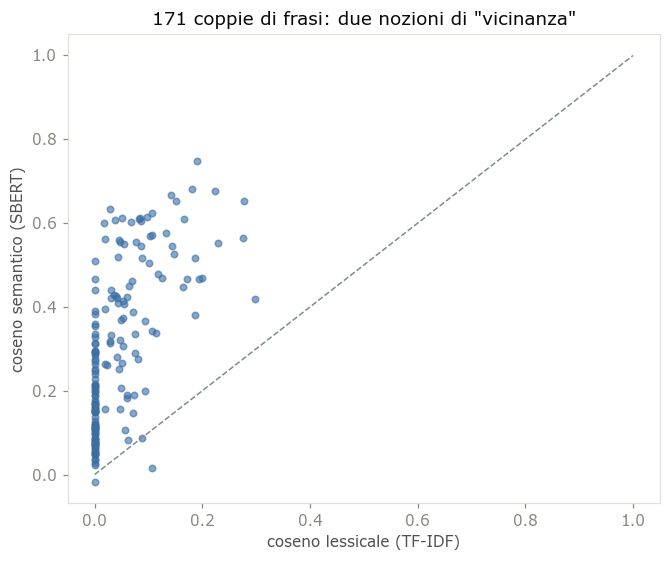

Coppie senza alcun termine in comune (coseno lessicale = 0): 86 su 171; di queste, con coseno SBERT > 0,3: 11
Coseno medio su tutte le coppie: SBERT 0.299 | TF-IDF 0.045

Le 2 coppie con il maggiore divario semantica − lessico (parafrasi che il TF-IDF non vede):
  (0, 3): SBERT 0.63 vs TF-IDF 0.03
    [0] UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesperson f…
    [3] This picture has itself caused scandal in the UK, as it was a gay kiss that was broadcast before the watershed…
  (3, 14): SBERT 0.60 vs TF-IDF 0.02
    [3] This picture has itself caused scandal in the UK, as it was a gay kiss that was broadcast before the watershed…
    [14] Here is a report on the John Snow Kiss-In from the Guardian, featuring an interview with Mr Shetler:
|| News |…


In [5]:
coppie = np.triu_indices(N, 1)                    # metà superiore, senza diagonale
x_lex, y_sem = S_lex[coppie], S_sem[coppie]

fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.scatter(x_lex, y_sem, s=18, alpha=.6, color='#3b6ea5')
ax.plot([0, 1], [0, 1], ls='--', color='#7f8c8d', lw=1)
ax.set_xlabel('coseno lessicale (TF-IDF)'); ax.set_ylabel('coseno semantico (SBERT)')
ax.set_title(f'{len(x_lex)} coppie di frasi: due nozioni di "vicinanza"')
plt.tight_layout(); plt.show()

zero = x_lex == 0
print(f'Coppie senza alcun termine in comune (coseno lessicale = 0): {zero.sum()} su {len(x_lex)}; '
      f'di queste, con coseno SBERT > 0,3: {(y_sem[zero] > 0.3).sum()}')
print(f'Coseno medio su tutte le coppie: SBERT {y_sem.mean():.3f} | TF-IDF {x_lex.mean():.3f}')
print('\nLe 2 coppie con il maggiore divario semantica − lessico (parafrasi che il TF-IDF non vede):')
for p in np.argsort(-(y_sem - x_lex))[:2]:
    a, b = int(coppie[0][p]), int(coppie[1][p])
    print(f'  ({a}, {b}): SBERT {S_sem[a, b]:.2f} vs TF-IDF {S_lex[a, b]:.2f}')
    print(f'    [{a}] {frasi[a][:110]}…\n    [{b}] {frasi[b][:110]}…')

**Cosa abbiamo visto.** Quasi tutti i punti stanno **sopra la diagonale**: SBERT trova vicine molte coppie
che per il TF-IDF sono estranee (asse verticale a sinistra). È il motivo per cui il metodo è interessante su
Multi-News, dove fonti diverse raccontano lo stesso fatto riformulandolo. Il rovescio della medaglia: in
questo spazio "tutto somiglia un po' a tutto" (coseno medio alto), e i gruppi andranno cercati in differenze
relativamente piccole.

Con queste coordinate le frasi sono **punti** in ℝ³⁸⁴. Il clustering cerca di raggrupparli: lo si può fare in
due modi molto diversi, che sono le due varianti del benchmark.

## 4. Clustering con K-means (`sbert_kmeans`)
K-means cerca `k` **centroidi** c₁…c_k e assegna ogni frase al più vicino, in modo da minimizzare
l'**inerzia** (somma delle distanze al quadrato):

> inerzia = Σᵢ ‖eᵢ − c_{gruppo(i)}‖²

Non esiste una formula chiusa: si usa l'**algoritmo di Lloyd**, che alterna due passi finché nulla cambia:

1. **assegnazione** — ogni frase va al centroide più vicino;
2. **aggiornamento** — ogni centroide diventa la **media** delle frasi del suo gruppo.

Ogni passo non può far salire l'inerzia, quindi l'algoritmo converge, ma a un **minimo locale** che dipende
dal punto di partenza. Per questo `sklearn.KMeans` usa due accorgimenti: un'inizializzazione furba
(*k-means++*, centroidi iniziali lontani tra loro) e **`n_init=10`** ripartenze, tenendo quella con inerzia
minima. Il benchmark usa `KMeans(n_clusters=11, random_state=42, n_init=10)`.

Riscriviamo Lloyd **a mano**, partendo da `k` frasi scelte a caso (più ingenuo di k-means++), e lo facciamo
girare da 10 punti di partenza diversi.

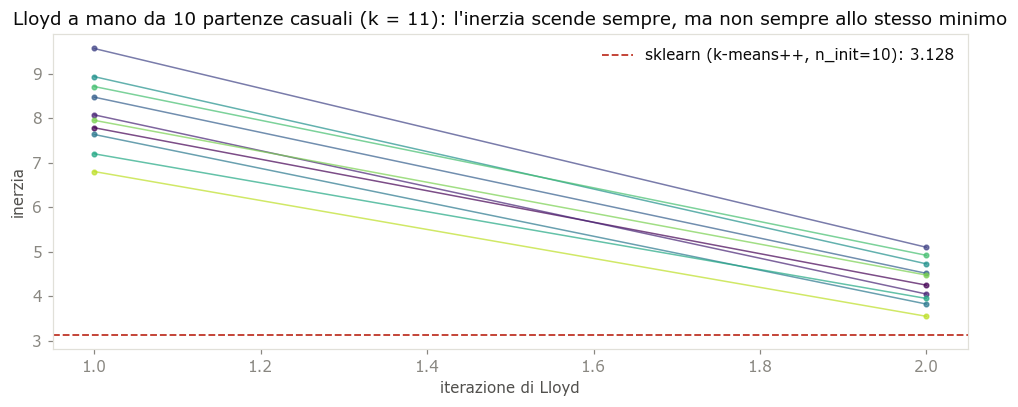

Inerzia finale delle 10 partenze a mano: min 3.545, max 5.096 | sklearn: 3.128
✔ sklearn: ogni frase è già assegnata al centroide più vicino, ogni centroide è già la media del suo gruppo (punto fisso di Lloyd), e l'inerzia coincide con la formula

Taglie dei 11 gruppi K-means: [1, 4, 4, 2, 1, 1, 1, 2, 1, 1, 1] | singoletti: 7


In [6]:
k = max(1, min(N_CLUSTER, N))                     # come il benchmark: k non supera il numero di frasi

def lloyd_a_mano(E, k, rng, max_iter=100):
    """K-means (Lloyd) scritto a mano. Partenza: k frasi a caso come centroidi iniziali."""
    C = E[rng.choice(len(E), k, replace=False)].copy()
    storia = []
    for _ in range(max_iter):
        D = ((E[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)        # (N, k) distanze al quadrato
        etichette = D.argmin(axis=1)                                    # 1. assegnazione
        storia.append(float(D[np.arange(len(E)), etichette].sum()))     #    inerzia corrente
        nuovi = np.array([E[etichette == c].mean(axis=0) if (etichette == c).any() else C[c] for c in range(k)])
        if np.allclose(nuovi, C):                                       # 2. aggiornamento: nulla cambia -> fine
            break
        C = nuovi
    return etichette, C, storia

rng = np.random.default_rng(SEED)
prove = [lloyd_a_mano(E, k, rng) for _ in range(10)]

km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(E)       # quello del benchmark
lab_km = km.labels_

fig, ax = plt.subplots(figsize=(9, 3.8))
for t, (_, _, storia) in enumerate(prove):
    ax.plot(range(1, len(storia) + 1), storia, marker='o', ms=3, lw=1, alpha=.7, color=plt.cm.viridis(t / 10))
ax.axhline(km.inertia_, color='#c0392b', ls='--', lw=1.2, label=f'sklearn (k-means++, n_init=10): {km.inertia_:.3f}')
ax.set_xlabel('iterazione di Lloyd'); ax.set_ylabel('inerzia')
ax.set_title(f'Lloyd a mano da 10 partenze casuali (k = {k}): l\'inerzia scende sempre, ma non sempre allo stesso minimo')
ax.legend(frameon=False); plt.tight_layout(); plt.show()

finali = sorted(storia[-1] for _, _, storia in prove)
print(f'Inerzia finale delle 10 partenze a mano: min {finali[0]:.3f}, max {finali[-1]:.3f} | sklearn: {km.inertia_:.3f}')

# Il risultato di sklearn è un PUNTO FISSO di Lloyd: rifare un passo non cambia nulla
D_km = ((E[:, None, :] - km.cluster_centers_[None, :, :]) ** 2).sum(axis=2)
assert (D_km.argmin(axis=1) == lab_km).all()
assert np.allclose([E[lab_km == c].mean(axis=0) for c in range(k)], km.cluster_centers_, atol=1e-5)
assert np.isclose(D_km.min(axis=1).sum(), km.inertia_, rtol=1e-4)
print('✔ sklearn: ogni frase è già assegnata al centroide più vicino, ogni centroide è già la media del suo gruppo '
      '(punto fisso di Lloyd), e l\'inerzia coincide con la formula')

taglie_km = np.bincount(lab_km, minlength=k)
print(f'\nTaglie dei {k} gruppi K-means: {taglie_km.tolist()} | singoletti: {(taglie_km == 1).sum()}')

**Cosa abbiamo visto.** Ogni curva scende in poche iterazioni e si ferma: è la garanzia di Lloyd. Ma le
curve si fermano a **quote diverse** — minimi locali diversi — ed è per questo che servono k-means++ e le
ripartenze. Il risultato di sklearn soddisfa esattamente le due condizioni di Lloyd (verificate con `assert`).

Le **taglie** dicono già molto: con 11 gruppi su 19 frasi la maggior parte dei gruppi ha 1-2 frasi. Un
**singoletto** è una frase che non somiglia abbastanza a nessun'altra: un frammento, un dettaglio, un pezzo
di boilerplate. Nel riassunto varrà quanto il gruppo che raccoglie il fatto principale.

Un dettaglio geometrico: i centroidi di K-means sono medie di vettori unitari, quindi hanno norma **< 1**
(stanno "dentro" la sfera). Per il **medoide** (sezione 6) questo non conta: la frase più vicina al centroide
in distanza euclidea è anche quella con coseno massimo, perché ‖e − c‖² = 1 + ‖c‖² − 2·e·c.

## 5. Clustering agglomerativo (`sbert_agglom`)
L'agglomerativo non cerca centroidi: costruisce i gruppi **dal basso**.

1. si parte con **N gruppi**, una frase ciascuno;
2. si fondono i **due gruppi più vicini**;
3. si ripete finché restano `k` gruppi.

Serve una distanza **tra gruppi**. Il benchmark usa `metric='cosine'` (distanza = 1 − coseno) e
`linkage='average'`: la distanza tra due gruppi è la **media** delle distanze tra tutte le coppie (una frase
per gruppo). Dopo una fusione non serve ricalcolare tutto: per l'average linkage vale la formula di
**Lance-Williams**

> d(A ∪ B, C) = ( |A| · d(A, C) + |B| · d(B, C) ) / ( |A| + |B| )

A differenza di K-means è **deterministico** (nessuna partenza casuale) e non assume gruppi "sferici".
Riscriviamolo a mano, conservando la storia delle fusioni.

In [7]:
def agglomerativo_a_mano(E, k):
    """Average linkage su distanza coseno, con aggiornamento di Lance-Williams. Ritorna etichette e storia."""
    n = len(E)
    D = np.clip(1.0 - E @ E.T, 0, None)                  # distanze coseno tra frasi
    np.fill_diagonal(D, np.inf)
    gruppi = {i: [i] for i in range(n)}                  # id gruppo -> frasi
    storia = []
    while len(gruppi) > k:
        attivi = sorted(gruppi)
        sub = D[np.ix_(attivi, attivi)]
        p = np.unravel_index(np.argmin(sub), sub.shape)
        a, b = sorted((attivi[p[0]], attivi[p[1]]))
        na, nb = len(gruppi[a]), len(gruppi[b])
        storia.append({'distanza': float(D[a, b]), 'gruppo A': gruppi[a][:], 'gruppo B': gruppi[b][:]})
        for c in attivi:                                  # Lance-Williams: distanze del nuovo gruppo (tenuto in a)
            if c not in (a, b):
                D[a, c] = D[c, a] = (na * D[a, c] + nb * D[b, c]) / (na + nb)
        D[b, :] = D[:, b] = np.inf
        gruppi[a] += gruppi.pop(b)
    etichette = np.empty(n, dtype=int)
    for c, membri in enumerate(gruppi.values()):
        etichette[membri] = c
    return etichette, storia

def partizione(etichette):
    """Forma canonica di una partizione (i numeri dei gruppi sono arbitrari)."""
    return sorted(tuple(int(i) for i in np.where(etichette == c)[0]) for c in set(etichette.tolist()))

lab_ag_mano, storia_ag = agglomerativo_a_mano(E, k)
lab_ag = AgglomerativeClustering(n_clusters=k, metric='cosine', linkage='average').fit_predict(E)
assert partizione(lab_ag_mano) == partizione(lab_ag)
print(f'✔ Le {len(storia_ag)} fusioni a mano danno la stessa partizione di sklearn AgglomerativeClustering')

display(pd.DataFrame([{'fusione': t, 'distanza (1 − coseno medio)': round(f['distanza'], 3),
                       'gruppo A': f['gruppo A'], 'gruppo B': f['gruppo B'],
                       'taglia dopo': len(f['gruppo A']) + len(f['gruppo B'])}
                      for t, f in enumerate(storia_ag, 1)]).set_index('fusione'))
taglie_ag = np.bincount(lab_ag, minlength=k)
print(f'Taglie dei {k} gruppi agglomerativi: {sorted(taglie_ag.tolist(), reverse=True)} | singoletti: {(taglie_ag == 1).sum()}')

✔ Le 8 fusioni a mano danno la stessa partizione di sklearn AgglomerativeClustering


,distanza (1 − coseno medio),gruppo A,gruppo B,taglia dopo
fusione,,,,
1,0.251,[8],[10],2
2,0.321,"[8, 10]",[12],3
3,0.347,[0],[11],2
4,0.386,"[0, 11]",[14],3
5,0.388,[15],[18],2
6,0.401,"[0, 11, 14]",[3],4
7,0.436,"[0, 11, 14, 3]",[17],5
8,0.462,"[0, 11, 14, 3, 17]",[16],6


Taglie dei 11 gruppi agglomerativi: [6, 3, 2, 1, 1, 1, 1, 1, 1, 1, 1] | singoletti: 8


**Leggere la tabella.** Le prime fusioni uniscono le coppie di frasi più simili (distanza piccola); più
avanti si fondono **gruppi già formati**, e la distanza cresce. Ci si ferma quando restano `k` gruppi: le
frasi mai fuse restano **singoletti**.

Il **dendrogramma** mostra la stessa storia per intero (calcolato con `scipy`, stesso average linkage
coseno): ogni giunzione è una fusione, alla quota della sua distanza. Tagliare l'albero all'altezza della
linea rossa lascia esattamente `k` gruppi.

✔ le quote delle prime N − k fusioni di scipy coincidono con quelle calcolate a mano


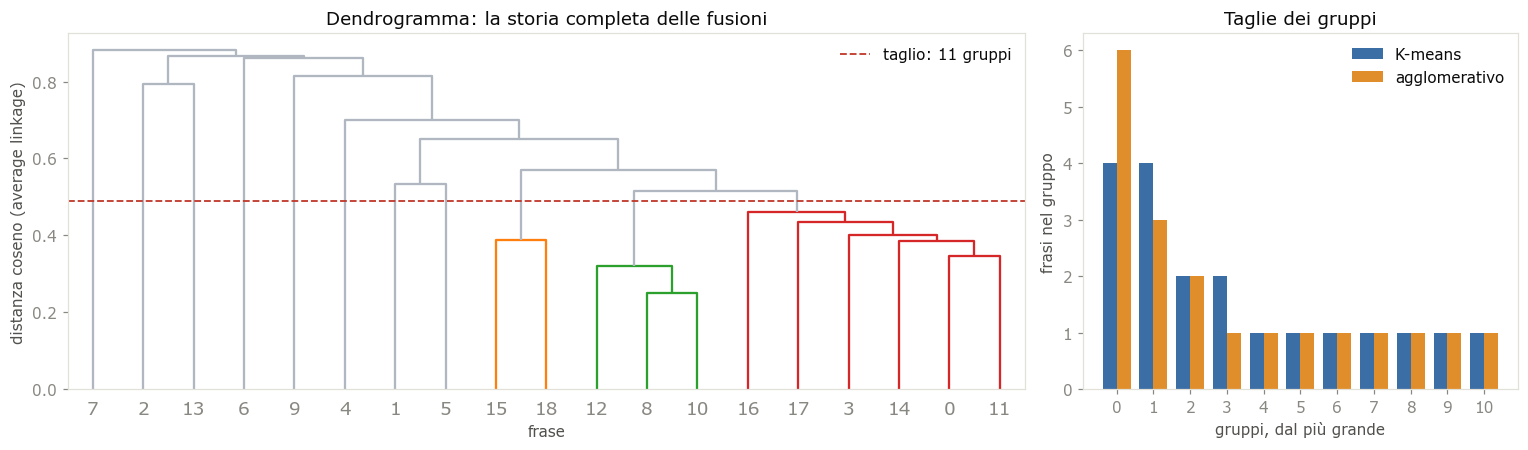

In [8]:
Zl = linkage(E, method='average', metric='cosine')
assert np.allclose(sorted(Zl[:N - k, 2]), sorted(f['distanza'] for f in storia_ag), atol=1e-5)
print('✔ le quote delle prime N − k fusioni di scipy coincidono con quelle calcolate a mano')
taglio = (Zl[N - k - 1, 2] + Zl[N - k, 2]) / 2 if k > 1 else Zl[-1, 2] + 0.01

fig, assi = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [2.2, 1]})
dendrogram(Zl, labels=list(range(N)), color_threshold=taglio, above_threshold_color='#b0b7c0', ax=assi[0])
assi[0].axhline(taglio, color='#c0392b', ls='--', lw=1.2, label=f'taglio: {k} gruppi')
assi[0].set_xlabel('frase'); assi[0].set_ylabel('distanza coseno (average linkage)')
assi[0].set_title('Dendrogramma: la storia completa delle fusioni'); assi[0].legend(frameon=False)

w = .38
ordine_km, ordine_ag = sorted(taglie_km, reverse=True), sorted(taglie_ag, reverse=True)
assi[1].bar(np.arange(k) - w / 2, ordine_km, w, color='#3b6ea5', label='K-means')
assi[1].bar(np.arange(k) + w / 2, ordine_ag, w, color='#e08e2b', label='agglomerativo')
assi[1].set_xlabel('gruppi, dal più grande'); assi[1].set_ylabel('frasi nel gruppo'); assi[1].set_xticks(range(k))
assi[1].set_title('Taglie dei gruppi'); assi[1].legend(frameon=False)
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Le due partizioni hanno una **forma diversa**. L'average linkage tende a far
crescere un gruppo **grande** che assorbe via via le frasi del tema principale, mentre le frasi "strane"
restano isolate fino alla fine: ne escono un gruppo molto popolato e diversi **singoletti**. K-means,
che minimizza l'inerzia, distribuisce le frasi in modo più **equilibrato** (spezzare un gruppo grande
abbassa molto l'inerzia).

Non è una particolarità di questa riga. Su un campione di 193 righe di test (verifica indicativa, fuori
dal benchmark) con 11 gruppi il gruppo più grande raccoglie in media il **47%** delle frasi con
l'agglomerativo contro il **20%** con K-means, e i singoletti sono in media **4,7 su 11** contro **1,9**. I
singoletti sono frasi corte (~15 parole in media): ne riparleremo nella sezione 13.

## 6. Centroidi e medoidi: un rappresentante per gruppo
Un riassunto estrattivo può solo **copiare frasi esistenti**, quindi da ogni gruppo serve una frase vera.
Per ogni gruppo il benchmark (`centroidi_e_medoidi` del notebook 16):

1. calcola il **centroide** = media degli embedding del gruppo, **ri-normalizzata** a norma 1 (un punto
   "medio" che non corrisponde ad alcuna frase);
2. prende il **medoide** = la frase del gruppo con **coseno massimo** col centroide, cioè il rappresentante
   più tipico di quel sottotema.

Per un singoletto il medoide è ovviamente la frase stessa, con coseno 1. Calcoliamo tutto a mano per la
variante scelta (`VARIANTE`).

In [9]:
ETICHETTE = {'sbert_kmeans': lab_km, 'sbert_agglom': lab_ag}
etichette = ETICHETTE[VARIANTE]

def centroidi_e_medoidi_a_mano(E, etichette):
    centroidi, medoidi, vicinanze = {}, {}, {}
    for c in sorted(set(etichette.tolist())):
        membri = np.where(etichette == c)[0]
        centro = E[membri].mean(axis=0)
        centro = centro / np.linalg.norm(centro)          # ri-normalizzato
        sim = E[membri] @ centro                          # coseni (gli embedding hanno norma 1)
        centroidi[c], medoidi[c], vicinanze[c] = centro, int(membri[np.argmax(sim)]), sim
    return centroidi, medoidi, vicinanze

centroidi, medoidi, vicinanze = centroidi_e_medoidi_a_mano(E, etichette)

# il medoide è anche la frase più vicina al centroide NON normalizzato in distanza euclidea (vedi sezione 4)
for c, i in medoidi.items():
    membri = np.where(etichette == c)[0]
    media = E[membri].mean(axis=0)
    assert membri[np.argmin(((E[membri] - media) ** 2).sum(axis=1))] == i
print('✔ medoide per coseno col centroide normalizzato = frase più vicina alla media in distanza euclidea')

taglie = {c: int((etichette == c).sum()) for c in medoidi}
righe = []
for c in sorted(medoidi, key=lambda c: -taglie[c]):
    i = medoidi[c]
    righe.append({'gruppo': f'K{c}', 'frasi nel gruppo': taglie[c],
                  'membri': [int(x) for x in np.where(etichette == c)[0]],
                  'medoide': i, 'coseno col centroide': round(float(vicinanze[c].max()), 3),
                  'parole': len(frasi[i].split()), 'testo del medoide': frasi[i][:70] + '…'})
print(f'{VARIANTE}: {len(medoidi)} gruppi, ordinati dal più grande')
display(pd.DataFrame(righe).set_index('gruppo'))

✔ medoide per coseno col centroide normalizzato = frase più vicina alla media in distanza euclidea
sbert_kmeans: 11 gruppi, ordinati dal più grande


,frasi nel gruppo,membri,medoide,coseno col centroide,parole,testo del medoide
gruppo,,,,,,
K1,4,"[0, 3, 16, 17]",0,0.845,60,"UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged …"
K2,4,"[8, 10, 11, 12]",8,0.889,37,"Secondly, the removal of the Facebook John Snow Kiss-In event: \n \n It …"
K3,2,"[5, 14]",5,0.886,25,"In relation to the John Snow Kiss-In event, I used this particular pho…"
K7,2,"[15, 18]",15,0.898,25,"""The photo in question does not violate our Statement of Rights and Re…"
K0,1,[9],9,1.000,16,"Paul Shetler, the organizer, left this comment on the previous thread:…"
K4,1,[2],2,1.000,23,I am not a regular viewer so I can’t say if the man on the right is an…
K5,1,[7],7,1.000,3,Oh the irony…
K6,1,[6],6,1.000,15,The photos I had considered using before I chose that one are much mor…
K8,1,[4],4,1.000,21,"However, since this episode aired (October 2008) Christian now has a b…"


**Leggere la tabella.** Un medoide con coseno alto in un gruppo **numeroso** è una scelta solida: la frase
riassume bene molte altre. Un singoletto ha coseno 1,000 per costruzione, ma non perché sia
rappresentativo: è solo una frase che non somiglia a nulla. Il metodo li tratta allo stesso modo — **un
posto a testa**.

La mappa qui sotto proietta lo spazio a 384 dimensioni su **due** con la PCA. È una compressione (due punti
vicini nel grafico potrebbero non esserlo davvero): va letta come una mappa indicativa. Colore + etichetta
`K…` = gruppo; stella = centroide; cerchio bordato di nero = medoide.

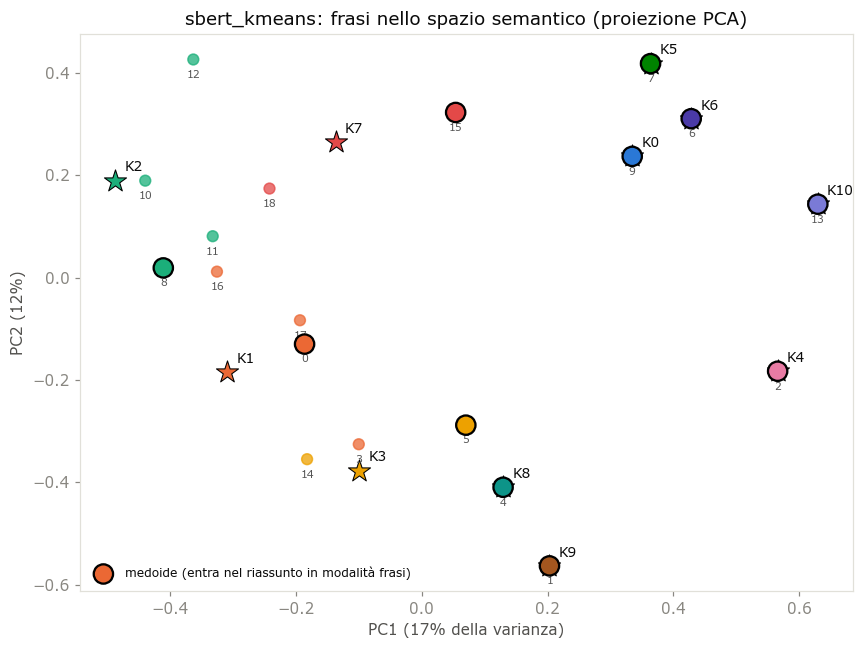

In [10]:
COLORI = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948', '#0d9488',
          '#a3561f', '#7a7ad6', '#5f6b7a', '#b5446e', '#3f8f3f', '#c28e0e']
col = lambda c: COLORI[int(c) % len(COLORI)]

pca = PCA(n_components=2, random_state=SEED)
XY = pca.fit_transform(E)
CXY = pca.transform(np.vstack([centroidi[c] for c in sorted(centroidi)]))
sel = np.zeros(N, dtype=bool); sel[list(medoidi.values())] = True

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(XY[~sel, 0], XY[~sel, 1], s=50, c=[col(c) for c in etichette[~sel]], alpha=.75, zorder=2)
ax.scatter(XY[sel, 0], XY[sel, 1], s=160, c=[col(c) for c in etichette[sel]], edgecolors='black', linewidths=1.5,
           zorder=4, label='medoide (entra nel riassunto in modalità frasi)')
for n_, c in enumerate(sorted(centroidi)):
    ax.scatter(*CXY[n_], s=230, marker='*', color=col(c), edgecolors='black', linewidths=.7, zorder=3)
    ax.annotate(f'K{c}', CXY[n_], xytext=(6, 6), textcoords='offset points', fontsize=9)
for i in range(N):
    ax.annotate(str(i), XY[i], xytext=(0, -12), textcoords='offset points', fontsize=7, ha='center', color='#555')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} della varianza)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
ax.set_title(f'{VARIANTE}: frasi nello spazio semantico (proiezione PCA)'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Le prime due componenti spiegano una quota piccola della varianza: in 384
dimensioni i gruppi possono essere ben separati anche se nel piano si sovrappongono. Si vede però il
meccanismo: ogni stella cade "in mezzo" al suo gruppo, e il medoide è il punto più vicino a lei. I
singoletti sono punti isolati con la stella sopra.

### Una trappola: i gruppi di due frasi
Nella tabella i gruppi da 2 frasi hanno un medoide, ma la scelta è un **pareggio esatto**. Con due vettori
unitari a e b il centroide normalizzato è c = (a + b) / ‖a + b‖, e

> a · c = (1 + a·b) / ‖a + b‖ = b · c

cioè le due frasi sono **ugualmente** vicine al centroide. Il medoide lo decide l'ultima cifra dei calcoli
in virgola mobile: basta un encoding su GPU invece che su CPU, o un'altra versione di una libreria, perché
`argmax` scelga l'altra frase. Verifichiamolo.

In [11]:
for c in [c for c in medoidi if taglie[c] == 2]:
    a_, b_ = (int(x) for x in np.where(etichette == c)[0])
    ca, cb = float(E[a_] @ centroidi[c]), float(E[b_] @ centroidi[c])
    teorico = (1 + E[a_] @ E[b_]) / np.linalg.norm(E[a_] + E[b_])
    print(f'K{c}: frase {a_} coseno {ca:.10f} | frase {b_} coseno {cb:.10f} | (1 + a·b)/‖a + b‖ = {teorico:.10f} '
          f'| differenza {abs(ca - cb):.1e} → medoide {medoidi[c]}')

K3: frase 5 coseno 0.8855316043 | frase 14 coseno 0.8855316043 | (1 + a·b)/‖a + b‖ = 0.8855316043 | differenza 0.0e+00 → medoide 5
K7: frase 15 coseno 0.8976968527 | frase 18 coseno 0.8976967931 | (1 + a·b)/‖a + b‖ = 0.8976967931 | differenza 6.0e-08 → medoide 15


**Cosa abbiamo visto.** Le differenze sono nulle o dell'ordine di 10⁻⁸, puro rumore numerico (a pareggio esatto `argmax` prende la prima frase). Nel benchmark questo
ha un effetto visibile proprio su questa riga: nella corsa `test_budgetref` salvata in `results/summaries/` il
gruppo {15, 18} ha avuto come medoide la **18** (68 parole) invece della 15 (25 parole), e il riassunto a
budget è diverso da quello che otteniamo qui (la sezione 9 lo segnala). Non è un errore di nessuna delle due
corse: il metodo, su questi gruppi, **non è definito**. Su una riga tipica (~50 frasi, 11 gruppi) i gruppi
di due frasi sono meno frequenti, ma esistono.

## 7. L'ordine di selezione
Il metodo produce un **ordine** delle frasi; la `MODALITA` deciderà dove tagliarlo (sezione 8).

- **Modalità `'frasi'`** (ambito `test`): l'ordine è semplicemente l'elenco dei **medoidi**, uno per gruppo.
  Con `k = 11` sono 11 frasi; non conta in che ordine li si elenca, perché entrano tutti.
- **Modalità `'budget'`** (ambito `test_budgetref`): il budget in parole può essere minore o maggiore dei
  medoidi, quindi serve un ordine **di priorità** più lungo (`ordine_rappresentanti` del notebook 16), **a
  giri**:
  - 1° giro: il medoide di ogni gruppo, **gruppi più grandi prima**;
  - 2° giro: la *seconda* frase più vicina al centroide di ogni gruppo (stesso ordine dei gruppi);
  - … finché tutte le frasi sono in elenco.

Il primo giro coincide con la selezione storica; se il budget è piccolo, a restare fuori sono i medoidi dei
gruppi **più piccoli** (spesso singoletti); se è grande, si continua con altri rappresentanti dei sottotemi
invece di fermarsi a 11 frasi. Il numero di gruppi resta 11: è strutturale (issue #14).

In [12]:
def ordine_a_giri(etichette, vicinanze):
    """Ordine a giri scritto a mano, conservando giro e gruppo di ogni frase."""
    per_gruppo = {c: [int(m) for m in np.where(etichette == c)[0][np.argsort(-vicinanze[c])]] for c in vicinanze}
    gruppi_ordinati = sorted(per_gruppo, key=lambda c: -len(per_gruppo[c]))     # sort stabile: a parità, id crescente
    righe = []
    for giro in range(max(len(v) for v in per_gruppo.values())):
        for c in gruppi_ordinati:
            if giro < len(per_gruppo[c]):
                righe.append({'giro': giro + 1, 'gruppo': f'K{c}', 'taglia': len(per_gruppo[c]), 'frase': per_gruppo[c][giro]})
    return righe

righe_ordine = ordine_a_giri(etichette, vicinanze)
ordine_giri = [r['frase'] for r in righe_ordine]
assert sorted(ordine_giri) == list(range(N))
assert set(ordine_giri[:len(medoidi)]) == set(medoidi.values())
print(f'✔ l\'ordine a giri contiene tutte le {N} frasi una volta sola, e il 1° giro sono esattamente i {len(medoidi)} medoidi')
tab_ordine = pd.DataFrame(righe_ordine)
tab_ordine['parole'] = [len(frasi[i].split()) for i in tab_ordine['frase']]
tab_ordine['parole cumulate'] = tab_ordine['parole'].cumsum()
tab_ordine['testo'] = [frasi[i][:60] + '…' for i in tab_ordine['frase']]
tab_ordine.index = pd.RangeIndex(1, len(tab_ordine) + 1, name='posizione')
display(tab_ordine)

✔ l'ordine a giri contiene tutte le 19 frasi una volta sola, e il 1° giro sono esattamente i 11 medoidi


,giro,gruppo,taglia,frase,parole,parole cumulate,testo
posizione,,,,,,,
1,1,K1,4,0,60,60,"UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, mi…"
2,1,K2,4,8,37,97,"Secondly, the removal of the Facebook John Snow Kiss-In even…"
3,1,K3,2,5,25,122,"In relation to the John Snow Kiss-In event, I used this part…"
4,1,K7,2,15,25,147,"""The photo in question does not violate our Statement of Rig…"
5,1,K0,1,9,16,163,"Paul Shetler, the organizer, left this comment on the previo…"
6,1,K4,1,2,23,186,I am not a regular viewer so I can’t say if the man on the r…
7,1,K5,1,7,3,189,Oh the irony…
8,1,K6,1,6,15,204,The photos I had considered using before I chose that one ar…
9,1,K8,1,4,21,225,"However, since this episode aired (October 2008) Christian n…"


**Leggere la tabella.** Le prime righe sono i medoidi dei gruppi grandi; i singoletti chiudono il primo
giro; dal secondo giro compaiono solo i gruppi con almeno due frasi. La colonna *parole cumulate* mostra
dove cadrà il taglio a budget (sezione 8).

Verifichiamo ora che tutto questo **coincida con l'implementazione del benchmark**. Qui sotto
`segmenta`, `codifica`, `cluster_kmeans`, `cluster_agglomerativo`, `centroidi_e_medoidi`,
`analizza_clustering`, `ordine_rappresentanti` e `make_genera` sono copiate **identiche** dal notebook 16:
se un giorno le due divergessero, queste `assert` si romperebbero.

In [13]:
# --- copia fedele del codice di produzione (notebooks/16_sbert_clustering.ipynb) ---------------------
STOP_WORDS = ['en']
METODO_KMEANS = 'sbert_kmeans'
METODO_AGGLOM = 'sbert_agglom'


def segmenta(documento):
    """Frasi del cluster con la segmentazione di psr.summarization (come TextRank/LexRank).

    `s.original` e' la lista delle frasi originali in ordine di documento. Si scartano
    le stringhe vuote.
    """
    s = psr.summarization(documento, stop_words=STOP_WORDS)
    return [f.strip() for f in getattr(s, 'original', []) if f and f.strip()]


_sbert = {}


def codifica(frasi):
    """Embedding SBERT delle frasi, (n, dim), L2-normalizzati. Modello caricato una volta.

    La normalizzazione rende il prodotto scalare uguale alla cosine similarity: tutte le
    "vicinanze" del notebook sono quindi la stessa cosa, misurata in un modo solo.
    """
    if 'model' not in _sbert:
        from sentence_transformers import SentenceTransformer
        _sbert['model'] = SentenceTransformer(ST_MODEL, device=DEVICE)
    return _sbert['model'].encode(frasi, normalize_embeddings=True, show_progress_bar=False)


# --- I due algoritmi di clustering (unica differenza tra le varianti) -------
def cluster_kmeans(E, k):
    """K-means sugli embedding -> etichette di cluster. Distanza euclidea."""
    return KMeans(n_clusters=k, random_state=SEED, n_init=10).fit_predict(E)


def cluster_agglomerativo(E, k):
    """Clustering gerarchico agglomerativo, cosine + average linkage -> etichette."""
    return AgglomerativeClustering(n_clusters=k, metric='cosine',
                                   linkage='average').fit_predict(E)


ALGORITMI = {METODO_KMEANS: cluster_kmeans, METODO_AGGLOM: cluster_agglomerativo}


def centroidi_e_medoidi(E, etichette):
    """Centroide di ogni cluster e frase piu' vicina a esso (medoide).

    Il centroide e' la media degli embedding del cluster, ri-normalizzata: e' un punto
    "medio" che non corrisponde ad alcuna frase reale. Il medoide e' la frase VERA piu'
    vicina a quel punto, cioe' il rappresentante piu' tipico del sottotema; e' quella che
    finisce nel riassunto (un riassunto estrattivo puo' solo copiare frasi esistenti).
    """
    centroidi, medoidi, vicinanze = {}, {}, {}
    for c in sorted(set(int(x) for x in etichette)):
        membri = np.where(etichette == c)[0]
        centro = E[membri].mean(axis=0)
        norma = np.linalg.norm(centro)
        centro = centro / norma if norma > 0 else centro
        sim = E[membri] @ centro               # cosine, gli embedding sono normalizzati
        centroidi[c] = centro
        medoidi[c] = int(membri[int(np.argmax(sim))])
        vicinanze[c] = sim
    return centroidi, medoidi, vicinanze


def analizza_clustering(frasi, algoritmo=None, k=None, E=None):
    """Pipeline completa su un pool di frasi, con tutti gli artefatti intermedi.

    Ritorna `E` (embedding), `etichette`, `centroidi`, `medoidi` ({cluster: indice frase}),
    `vicinanze` e `k`. `E` puo' essere passata dall'esterno per non ricodificare le stesse
    frasi quando si confrontano i due algoritmi (lo fa la sezione di spiegazione).
    """
    algoritmo = cluster_kmeans if algoritmo is None else algoritmo
    k = N_CLUSTER if k is None else k
    E = codifica(frasi) if E is None else E
    k = max(1, min(k, len(frasi)))
    etichette = algoritmo(E, k)
    centroidi, medoidi, vicinanze = centroidi_e_medoidi(E, etichette)
    return {'E': E, 'etichette': etichette, 'centroidi': centroidi, 'medoidi': medoidi,
            'vicinanze': vicinanze, 'k': k}


def ordine_rappresentanti(art):
    """Ordine di selezione a giri per l'ambito a budget.

    1o giro: il medoide di ogni cluster, cluster piu' grandi prima; 2o giro: la seconda
    frase piu' vicina al centroide di ogni cluster; ... Il primo giro coincide con la
    selezione storica (un medoide per cluster), quindi a budget "piccolo" il metodo
    e' lo stesso di sempre; a budget grande continua con i rappresentanti successivi
    dei sottotemi invece di fermarsi a 11 frasi.
    """
    per_cluster = {}
    for c, sim in art['vicinanze'].items():
        membri = np.where(art['etichette'] == c)[0]
        per_cluster[c] = [int(membri[j]) for j in np.argsort(-sim)]
    cluster_ordinati = sorted(per_cluster, key=lambda c: -len(per_cluster[c]))
    ordine, giro = [], 0
    while any(giro < len(per_cluster[c]) for c in cluster_ordinati):
        ordine += [per_cluster[c][giro] for c in cluster_ordinati if giro < len(per_cluster[c])]
        giro += 1
    return ordine


def make_genera(metodo):
    """Crea genera(documento[, budget]) per una delle due varianti di clustering."""
    algoritmo = ALGORITMI[metodo]

    def genera(documento, budget=None):
        frasi = segmenta(documento)
        if budget is None and len(frasi) <= N_SENTENCES:
            return ' '.join(frasi)
        try:
            art = analizza_clustering(frasi, algoritmo=algoritmo)
            ordine = (list(art['medoidi'].values()) if budget is None
                      else ordine_rappresentanti(art))
        except ValueError:    # clustering non applicabile (es. embedding degeneri/nulli)
            ordine = range(len(frasi) if budget is not None else N_SENTENCES)
        if budget is not None:
            ordine = su.seleziona_per_budget(frasi, ordine, budget)
        return ' '.join(frasi[i] for i in sorted(ordine))
    return genera
# ---------------------------------------------------------------------------------------------------
_sbert['model'] = modello            # riusa l'encoder già caricato nella sezione 3

assert segmenta(documento) == frasi
assert np.allclose(codifica(frasi), E, atol=1e-6)
art = analizza_clustering(frasi, algoritmo=ALGORITMI[VARIANTE], E=E)
assert (art['etichette'] == etichette).all()
assert art['medoidi'] == medoidi
assert ordine_rappresentanti(art) == ordine_giri
for var in ALGORITMI:
    assert partizione(analizza_clustering(frasi, algoritmo=ALGORITMI[var], E=E)['etichette']) == partizione(ETICHETTE[var])
print(f'✔ Segmentazione, embedding, partizioni (entrambe le varianti), medoidi e ordine a giri coincidono con il notebook 16')

ORDINI = {}
for var in ALGORITMI:
    a_ = analizza_clustering(frasi, algoritmo=ALGORITMI[var], E=E)
    ORDINI[var] = {'frasi': list(a_['medoidi'].values()), 'budget': ordine_rappresentanti(a_)}

✔ Segmentazione, embedding, partizioni (entrambe le varianti), medoidi e ordine a giri coincidono con il notebook 16


### Intermezzo: l'effetto di `k`
Nel benchmark `k` **non è un iperparametro libero**: è il numero di frasi del riassunto (una per gruppo).
Vale la pena vedere però cosa succede al variare di `k`, perché spiega il comportamento del metodo. Per
ciascuna variante la tabella riporta i singoletti, la quota di frasi nel gruppo più grande, la lunghezza del
set di medoidi e la sua **ridondanza** (coseno semantico medio tra le frasi scelte, più basso = meno ripetitivo).

singoletti quota nel gruppo più grande  parole dei medoidi  ridondanza dei medoidi
k  variante                                                                                        
2  sbert_kmeans           0                         84%                  78                   0.366
   sbert_agglom           1                         95%                  65                   0.209
4  sbert_kmeans           1                         53%                 156                   0.222
   sbert_agglom           2                         79%                  87                   0.116
7  sbert_kmeans           3                         37%                 195                   0.153
   sbert_agglom           6                         68%                 147                   0.147
11 sbert_kmeans           7                         21%                 291                   0.196
   sbert_agglom           8                         32%                 317                   0.192
15 sbert_kmeans          12                         16%                 483                   0.261
   sbert_agglom          13                         16%                 456                   0.258

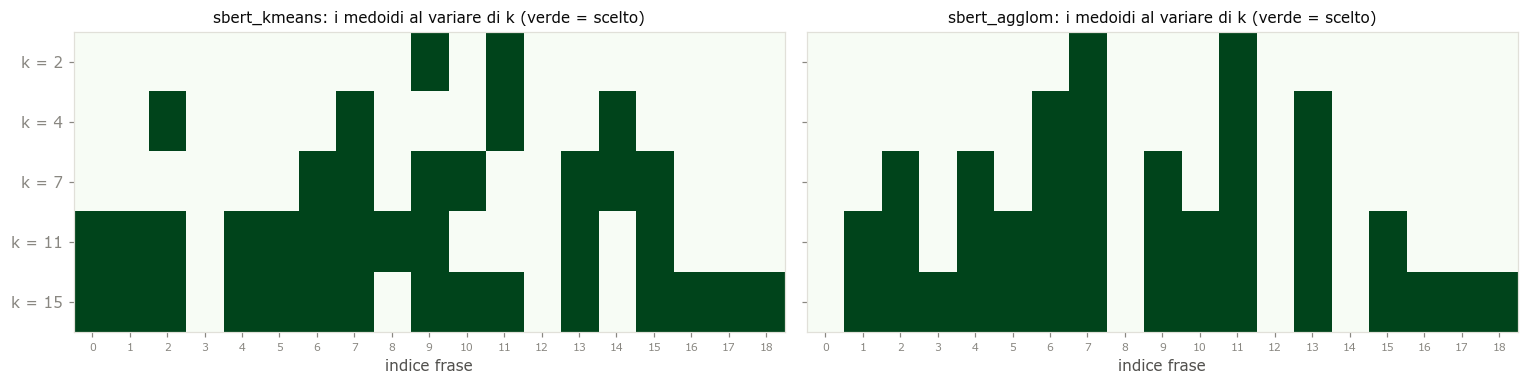

In [14]:
def ridondanza_media(indici, M=S_sem):
    coppie_ = [M[a][b] for t, a in enumerate(indici) for b in indici[t + 1:]]
    return float(np.mean(coppie_)) if coppie_ else 0.0

K_CONFRONTO = sorted({2, 4, 7, k, max(2, min(N - 1, 15))})
righe, scelte_k = [], {}
for k_ in K_CONFRONTO:
    for var, alg in ALGORITMI.items():
        a_ = analizza_clustering(frasi, algoritmo=alg, k=k_, E=E)
        tg = np.bincount(a_['etichette'])
        med = sorted(a_['medoidi'].values())
        scelte_k[(var, k_)] = med
        righe.append({'k': k_, 'variante': var, 'singoletti': int((tg == 1).sum()),
                      'quota nel gruppo più grande': f'{tg.max() / N:.0%}',
                      'parole dei medoidi': sum(len(frasi[i].split()) for i in med),
                      'ridondanza dei medoidi': round(ridondanza_media(med), 3)})
display(pd.DataFrame(righe).set_index(['k', 'variante']))

fig, assi = plt.subplots(1, 2, figsize=(14, 1.6 + 0.4 * len(K_CONFRONTO)), sharey=True)
for ax, var in zip(assi, ALGORITMI):
    M = np.zeros((len(K_CONFRONTO), N))
    for r_, k_ in enumerate(K_CONFRONTO):
        M[r_, scelte_k[(var, k_)]] = 1.0
    ax.imshow(M, cmap='Greens', vmin=0, vmax=1, aspect='auto')
    ax.set_yticks(range(len(K_CONFRONTO))); ax.set_yticklabels([f'k = {k_}' for k_ in K_CONFRONTO])
    ax.set_xticks(range(N)); ax.set_xticklabels(range(N), fontsize=7); ax.set_xlabel('indice frase')
    ax.set_title(f'{var}: i medoidi al variare di k (verde = scelto)', fontsize=10)
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Con `k` piccolo i gruppi sono grandi e i medoidi sono frasi **centrali** del tema
principale; al crescere di `k` entrano frasi via via più periferiche, e i singoletti si moltiplicano. Con
l'agglomerativo i singoletti compaiono **prima**: le frasi isolate restano tali fino alle ultime fusioni,
quindi qualunque `k` non piccolo le pesca tutte. Notare che `k` controlla insieme **quante** frasi e
**quanto granulari** sono i sottotemi: il metodo non può chiedere "pochi temi ma un riassunto lungo" — è
proprio per questo che la modalità a budget usa i giri.

## 8. Selezione delle frasi
L'ordine (`ordine`, quello di `VARIANTE`) viene tagliato secondo la `MODALITA`:

- **`'frasi'`**: si tengono gli 11 medoidi. Se il documento ha già ≤ 11 frasi, si prendono tutte (non c'è
  nulla da raggruppare);
- **`'budget'`**: si accumulano frasi **nell'ordine a giri** finché si raggiunge il **budget** = lunghezza
  in parole del riferimento (`su.seleziona_per_budget`: la frase che sfora viene inclusa solo se ne entra
  più della metà). Si usa solo la *lunghezza* del gold, mai il suo contenuto.

VARIANTE = 'sbert_kmeans' | MODALITA = 'budget': selezionate 5 frasi (163 parole) | budget = 168 parole


,giro,gruppo,taglia,frase,parole,parole cumulate,scelta,testo
posizione,,,,,,,,
1,1,K1,4,0,60,60,✔,"UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, mi…"
2,1,K2,4,8,37,97,✔,"Secondly, the removal of the Facebook John Snow Kiss-In even…"
3,1,K3,2,5,25,122,✔,"In relation to the John Snow Kiss-In event, I used this part…"
4,1,K7,2,15,25,147,✔,"""The photo in question does not violate our Statement of Rig…"
5,1,K0,1,9,16,163,✔,"Paul Shetler, the organizer, left this comment on the previo…"
6,1,K4,1,2,23,186,,I am not a regular viewer so I can’t say if the man on the r…
7,1,K5,1,7,3,189,,Oh the irony…
8,1,K6,1,6,15,204,,The photos I had considered using before I chose that one ar…
9,1,K8,1,4,21,225,,"However, since this episode aired (October 2008) Christian n…"


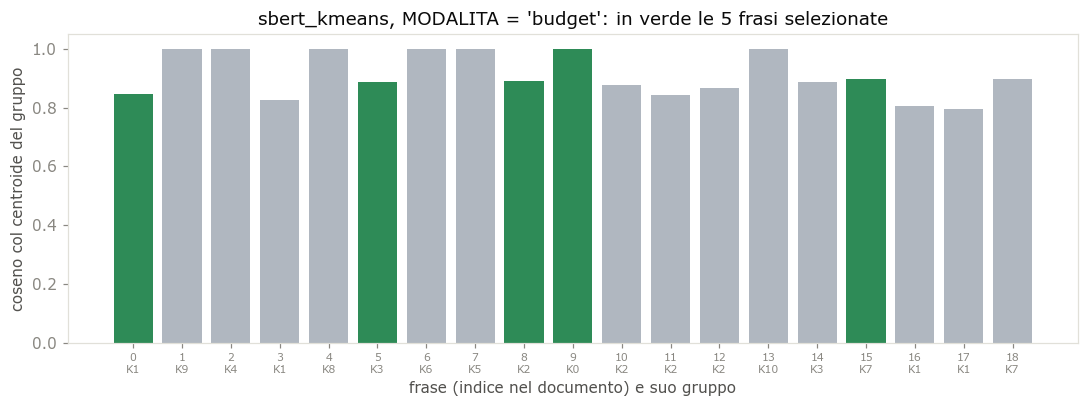

In [15]:
budget = su.budget_riferimento(esempio)                 # = parole del riferimento
idx_frasi = ORDINI[VARIANTE]['frasi'] if N > N_SENTENCES else list(range(N))
idx_budget = su.seleziona_per_budget(frasi, ORDINI[VARIANTE]['budget'], budget)
idx_scelti = idx_frasi if MODALITA == 'frasi' else idx_budget
selezionate = set(idx_scelti)
print(f"VARIANTE = '{VARIANTE}' | MODALITA = '{MODALITA}': selezionate {len(idx_scelti)} frasi "
      f"({sum(len(frasi[i].split()) for i in idx_scelti)} parole) | budget = {budget} parole")

tab_ordine['scelta'] = ['✔' if i in selezionate else '' for i in tab_ordine['frase']]
display(tab_ordine[['giro', 'gruppo', 'taglia', 'frase', 'parole', 'parole cumulate', 'scelta', 'testo']]
        .head(max(len(medoidi), len(idx_budget)) + 3))

coseno_proprio = np.array([float(E[i] @ centroidi[etichette[i]]) for i in range(N)])
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(N), coseno_proprio, color=['#2e8b57' if i in selezionate else '#b0b7c0' for i in range(N)])
ax.set_xticks(range(N)); ax.set_xticklabels([f'{i}\nK{etichette[i]}' for i in range(N)], fontsize=7)
ax.set_xlabel('frase (indice nel documento) e suo gruppo'); ax.set_ylabel('coseno col centroide del gruppo')
ax.set_title(f"{VARIANTE}, MODALITA = '{MODALITA}': in verde le {len(selezionate)} frasi selezionate")
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** A differenza di LSA o Centroid+MMR non esiste un punteggio globale "più alto =
migliore": il coseno col centroide confronta una frase solo con il **proprio** gruppo, e una frase molto
tipica di un gruppo grande può restare fuori perché il suo gruppo ha già il medoide. In modalità
`'budget'` sulla riga 50492 con K-means il budget (168 parole) basta per 5 frasi: i medoidi dei quattro
gruppi con più di una frase e uno solo dei sette singoletti. Come per gli altri estrattivi non c'è alcun criterio di
*posizione* (come nel baseline First-k).

## 9. Generazione del riassunto finale
Il riassunto è la concatenazione delle frasi **originali** scelte, **rimesse in ordine di documento**
(`sorted`): come Centroid+MMR e LSA, e a differenza di TextRank/LexRank (che emettono per punteggio
decrescente). In modalità `'budget'` si applica poi il **tetto**: troncamento alle prime
`round(1,25 × lunghezza del riferimento)` parole (`su.tetto_riferimento`), come fa il benchmark prima di
calcolare le metriche. Verifichiamo che il testo coincida con quello di `genera()` del notebook 16 e,
se il repository contiene i riassunti del benchmark, con quello salvato in `results/summaries/`.

In [16]:
tetto = su.tetto_riferimento(esempio)         # round(1,25 × riferimento)
genera_produzione = make_genera(VARIANTE)

riassunto_frasi = ' '.join(frasi[i] for i in sorted(idx_frasi))
riassunto_budget = ' '.join(frasi[i] for i in sorted(idx_budget))
riassunto_budget_tetto = su.tronca_parole(riassunto_budget, tetto)

# verifica contro la funzione di produzione (stesso testo che finirebbe in results/summaries/)
assert riassunto_frasi == genera_produzione(documento)
assert riassunto_budget == genera_produzione(documento, budget=budget)
print(f"✔ 'frasi' e 'budget' coincidono con genera() del notebook 16 ({VARIANTE})")

# confronto (informativo) con i riassunti del benchmark, se presenti: nei gruppi di due frasi
# il medoide è un pareggio esatto (sezione 6), quindi qui non si usa un assert
for ambito, testo_qui in (('test', riassunto_frasi), ('test_budgetref', riassunto_budget)):
    percorso = P['summaries_dir'] / f'{VARIANTE}_{ambito}.tsv'
    if percorso.exists():
        salvato = su.carica_riassunti(percorso).get(ROW_ID)
        esito = 'identico ✔' if salvato == testo_qui else 'diverso (medoide di un gruppo di due frasi: vedi la sezione 6)'
        print(f'  results/summaries/{percorso.name}, riga {ROW_ID}: {esito}')

riassunto = riassunto_frasi if MODALITA == 'frasi' else riassunto_budget_tetto   # ← quello che si valuta
if MODALITA == 'budget':
    print(f'  budget = {budget} parole | tetto = {tetto} parole | prima del tetto: {len(riassunto_budget.split())} parole')
print(f"\nRIASSUNTO — {VARIANTE}, MODALITA '{MODALITA}' ({len(riassunto.split())} parole, ordine di documento):\n")
print(textwrap.fill(riassunto, 110))

✔ 'frasi' e 'budget' coincidono con genera() del notebook 16 (sbert_kmeans)
  results/summaries/sbert_kmeans_test.tsv, riga 50492: identico ✔


  results/summaries/sbert_kmeans_test_budgetref.tsv, riga 50492: diverso (medoide di un gruppo di due frasi: vedi la sezione 6)
  budget = 168 parole | tetto = 210 parole | prima del tetto: 163 parole

RIASSUNTO — sbert_kmeans, MODALITA 'budget' (163 parole, ordine di documento):

UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesperson
for gay rights overnight on Boing Boing     It’s time to clarify a few details about the controversial “Hey
Facebook what’s SO wrong with a pic of two men kissing?” story, as it now beginning to be reported in the
mainstream media, and not always correctly In relation to the John Snow Kiss-In event, I used this particular
photo because I considered it to be quite mild (no groping, no tongues) Secondly, the removal of the Facebook
John Snow Kiss-In event:     It turns out that the Facebook event for the John Snow Kiss-In was not blocked by
Facebook, but made private by the creator of the event itself Pa

**Cosa abbiamo visto.** Il riassunto è fatto di frasi copiate parola per parola, quindi può contenere
**riferimenti sospesi** ("he", "the company" senza antecedente). La partizione garantisce che le frasi
vengano da gruppi **diversi**, non che siano le più importanti: un gruppo di boilerplate ("Page 1 of 1",
menu del sito, "UPDATE: …") ha diritto al suo posto come gli altri. Infine il testo grezzo di Multi-News
contiene **rumore di scraping**: se forma un gruppo a sé, il suo medoide finisce nel riassunto.

## 10. Confronto con il riassunto di riferimento
Mettiamo a confronto il riassunto generato con quello umano e guardiamo le **lunghezze**
(la tabella mostra *entrambe* le modalità, la scelta è marcata da ◀): con 11 medoidi il metodo produce
riassunti più lunghi del riferimento (nel benchmark: ~264 parole per `sbert_kmeans`, ~216 per
`sbert_agglom`, contro ~215). Questo è un **confondente di lunghezza**: un riassunto più lungo ha più
probabilità di contenere parole del riferimento, e quindi *recall* più alta, indipendentemente dalla
qualità della selezione.

Per questo il progetto ha introdotto la **rigenerazione a budget** (issue #16, protocollo
*length-matched*): il budget è la **lunghezza in parole del riferimento** (si usa solo la
*lunghezza* del gold, mai il suo contenuto). Si accumulano le frasi **nell'ordine a giri** finché si
raggiunge il budget (`su.seleziona_per_budget`). Poi si applica il **tetto** a 1,25 × la lunghezza del
riferimento (`su.tetto_riferimento`), troncando alle prime parole.

Qui confrontiamo le versioni già calcolate nella sezione 9.

In [17]:
marca = {'frasi': ' ◀' if MODALITA == 'frasi' else '', 'budget': ' ◀' if MODALITA == 'budget' else ''}
lung = pd.DataFrame({
    'parole': [len(riferimento.split()), len(riassunto_frasi.split()), len(riassunto_budget.split()), len(riassunto_budget_tetto.split())],
    'frasi': ['—', len(idx_frasi), len(idx_budget), len(idx_budget)],
}, index=['riferimento umano', 'generato — 11 medoidi' + marca['frasi'], 'generato — budget (prima del tetto)',
          'generato — budget + tetto' + marca['budget']])
lung['rapporto col riferimento'] = (lung['parole'] / len(riferimento.split())).round(2)
display(lung)
print(f'budget = {budget} parole | tetto = {tetto} parole')

print('\n=== RIFERIMENTO UMANO ===');            print(textwrap.fill(riferimento, 110))
print(f"\n=== GENERATO — {VARIANTE}, MODALITA '{MODALITA}' ===");  print(textwrap.fill(riassunto, 110))

,parole,frasi,rapporto col riferimento
riferimento umano,168,—,1.00
generato — 11 medoidi,291,11,1.73
generato — budget (prima del tetto),163,5,0.97
generato — budget + tetto ◀,163,5,0.97


budget = 168 parole | tetto = 210 parole

=== RIFERIMENTO UMANO ===
It turns out Facebook is only guilty of about half of what it’s been accused of in the gay kiss incident. The
social networking site apologized yesterday for taking down an image used to promote a “kiss-in” event in
London. “The photo in question does not violate our Statement of Rights and Responsibilities, and was removed
in error,” the site said in a statement, according to the Advocate. But Facebook did not, as has been reported
in several places, take down the kiss-in event itself. Here’s what happened: The photo Facebook took down was
posted by the Dangerous Minds blog to promote the event. In its initial write-up about the incident, the blog
observed that the page organizing the protest had been taken down. But it was actually the organizer himself
who "removed" the event, Dangerous Minds clarified. Organizer Paul Shetler explains that he decided to switch
it from a public event to a private one, as "there were 

**Cosa abbiamo visto.** Il riassunto a 11 frasi è tipicamente **più lungo** del riferimento; quello a
budget ha una lunghezza paragonabile (la tabella mostra entrambi). Il riferimento, inoltre, è *abstractive*:
riformula, sintetizza e ordina le informazioni in modo che nessuna frase estratta potrà mai riprodurre alla
lettera. Questo pone un **limite superiore** alle metriche di sovrapposizione per qualsiasi metodo estrattivo.

## 11. Calcolo delle metriche di valutazione
Le metriche misurano la **sovrapposizione** tra riassunto generato e riferimento (testo
normalizzato: minuscole, senza punteggiatura, **con** stopword e numeri). Sono quelle di
`pyAutoSummarizer`, identiche per tutti i metodi del benchmark:

| metrica | cosa misura |
|---|---|
| **ROUGE-1 / ROUGE-2** | sovrapposizione di unigrammi / bigrammi. **Precision** = quota degli n-grammi del generato presenti nel riferimento; **Recall** = quota degli n-grammi del riferimento ritrovati nel generato; **F1** = media armonica |
| **ROUGE-L** | sottosequenza comune più lunga (LCS), sensibile all'ordine delle parole |
| **BLEU** | precisione di n-grammi (1-4) con penalità di brevità |
| **METEOR** | corrispondenza di parole con penalità per la frammentazione dei match |

⚠️ **Caveat della libreria:** il ROUGE-N di `pyAutoSummarizer` usa **insiemi di n-grammi
unici** (non i conteggi *clipped* del ROUGE ufficiale): i valori sono confrontabili tra i metodi
di questo progetto ma **non** con quelli della letteratura.

Prima un calcolo di ROUGE-1 **a mano**, per vedere cosa c'è dentro i numeri.

In [18]:
valutatore = su.crea_valutatore()

def normalizza(testo):
    return valutatore.clear_text([testo], stop_words=[], lowercase=True, rmv_accents=False,
                                 rmv_special_chars=True, rmv_numbers=False, rmv_custom_words=[])[0].split()

def rouge1_a_mano(generato, rif):
    g, r = set(normalizza(generato)), set(normalizza(rif))     # insiemi di unigrammi UNICI
    comuni = g & r
    p, rec = len(comuni) / len(g), len(comuni) / len(r)
    return 2 * p * rec / (p + rec), p, rec, len(g), len(r), len(comuni)

f1, p, rec, ng, nr, nc = rouge1_a_mano(riassunto, riferimento)
print(f"Generato ({VARIANTE}, MODALITA '{MODALITA}'): {ng} parole distinte | riferimento: {nr} parole distinte | in comune: {nc}")
print(f'precision = {nc}/{ng} = {p:.3f} | recall = {nc}/{nr} = {rec:.3f} | F1 = {f1:.3f}')

r1 = valutatore.rouge_N(riassunto, riferimento, n=1)          # (f1, precision, recall)
assert np.allclose([f1, p, rec], r1)
print('✔ Coincide con valutatore.rouge_N(…, n=1)')

Generato (sbert_kmeans, MODALITA 'budget'): 108 parole distinte | riferimento: 103 parole distinte | in comune: 43
precision = 43/108 = 0.398 | recall = 43/103 = 0.417 | F1 = 0.408
✔ Coincide con valutatore.rouge_N(…, n=1)


Ora tutte le metriche, per il riassunto a **11 medoidi** e per quello **a budget + tetto**
(le metriche dell'ambito `test_budgetref` del benchmark sono calcolate proprio sul testo dopo
il tetto). La colonna della modalità scelta è marcata da ◀; l'altra è lì per confronto.

,11 medoidi,budget + tetto ◀
ROUGE-1 F1,0.357,0.408
ROUGE-1 precision,0.282,0.398
ROUGE-1 recall,0.485,0.417
ROUGE-2 F1,0.156,0.207
ROUGE-2 precision,0.124,0.210
ROUGE-2 recall,0.210,0.204
ROUGE-L F1,0.149,0.194
ROUGE-L precision,0.117,0.195
ROUGE-L recall,0.205,0.193
BLEU,0.111,0.183


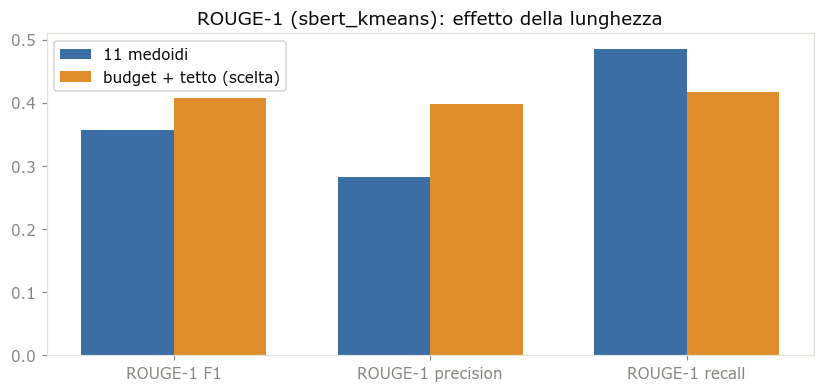

In [19]:
m11 = su.metriche_esempio(valutatore, riassunto_frasi, riferimento)
mbu = su.metriche_esempio(valutatore, riassunto_budget_tetto, riferimento)
m_scelta, m_altra = (m11, mbu) if MODALITA == 'frasi' else (mbu, m11)
assert np.isclose(m_scelta['rouge1_f1'], r1[0])   # coerente con il ROUGE-1 a mano della modalità scelta
et11 = '11 medoidi' + (' ◀' if MODALITA == 'frasi' else '')
etbu = 'budget + tetto' + (' ◀' if MODALITA == 'budget' else '')

ordine_col = ['rouge1_f1', 'rouge1_p', 'rouge1_r', 'rouge2_f1', 'rouge2_p', 'rouge2_r',
              'rougeL_f1', 'rougeL_p', 'rougeL_r', 'bleu', 'meteor', 'parole_generate']
tab_metriche = pd.DataFrame({et11: m11, etbu: mbu}).loc[ordine_col]
tab_metriche.index = ['ROUGE-1 F1', 'ROUGE-1 precision', 'ROUGE-1 recall', 'ROUGE-2 F1', 'ROUGE-2 precision', 'ROUGE-2 recall',
                      'ROUGE-L F1', 'ROUGE-L precision', 'ROUGE-L recall', 'BLEU', 'METEOR', 'parole generate']
display(tab_metriche.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
chiavi = ['rouge1_f1', 'rouge1_p', 'rouge1_r']
x = np.arange(len(chiavi)); w = .36
ax.bar(x - w / 2, [m11[k_] for k_ in chiavi], w, label=et11.replace(' ◀', ' (scelta)'), color='#3b6ea5')
ax.bar(x + w / 2, [mbu[k_] for k_ in chiavi], w, label=etbu.replace(' ◀', ' (scelta)'), color='#e08e2b')
ax.set_xticks(x); ax.set_xticklabels(['ROUGE-1 F1', 'ROUGE-1 precision', 'ROUGE-1 recall'])
ax.legend(); ax.set_title(f'ROUGE-1 ({VARIANTE}): effetto della lunghezza')
plt.show()

**Cosa abbiamo visto.** Con più parole la **recall** sale (si "pescano" più parole del
riferimento) ma la **precision** scende (molte parole in più non servono): la **F1** compensa i
due effetti ed è la metrica più onesta quando le lunghezze sono diverse. A parità di lunghezza
(budget), la differenza tra metodi riflette davvero la qualità della *selezione dei contenuti*.

## 12. Interpretazione dei risultati
Il commento seguente legge i numeri **di questa riga** (si aggiorna se cambi `ROW_ID`, `VARIANTE` o `MODALITA`).

In [20]:
nome_altra = 'budget + tetto' if MODALITA == 'frasi' else '11 medoidi'
dr, db = m_altra['rouge1_r'] - m_scelta['rouge1_r'], m_altra['rouge1_p'] - m_scelta['rouge1_p']
tg = np.bincount(etichette)
testo = f"""
**Riga {ROW_ID} — {VARIANTE} (k = {k} gruppi su {N} frasi) — MODALITA `'{MODALITA}'`.**

- Il clustering ha prodotto {(tg == 1).sum()} singoletti su {k} gruppi; il gruppo più grande raccoglie {tg.max()} frasi
  ({tg.max() / N:.0%} del pool).
- Il riassunto ha {m_scelta['parole_generate']} parole contro le {len(riferimento.split())} del riferimento
  ({m_scelta['parole_generate'] / len(riferimento.split()):.1f}×): ROUGE-1 recall = **{m_scelta['rouge1_r']:.3f}**,
  precision = **{m_scelta['rouge1_p']:.3f}**, F1 = **{m_scelta['rouge1_f1']:.3f}**.
- Per confronto, con la modalità *{nome_altra}* ({m_altra['parole_generate']} parole) la recall {'sale' if dr > 0 else 'scende'} a
  **{m_altra['rouge1_r']:.3f}** (Δ = {dr:+.3f}) e la precision {'sale' if db > 0 else 'scende'} a **{m_altra['rouge1_p']:.3f}**
  (Δ = {db:+.3f}): F1 = **{m_altra['rouge1_f1']:.3f}**.
- ROUGE-2 F1 = {m_scelta['rouge2_f1']:.3f} (modalità scelta): molto più bassa di ROUGE-1, perché le sequenze di **due parole**
  consecutive in comune col riferimento *astratto* sono rare — è tipico dei metodi estrattivi.
"""
display(Markdown(testo))


**Riga 50492 — sbert_kmeans (k = 11 gruppi su 19 frasi) — MODALITA `'budget'`.**

- Il clustering ha prodotto 7 singoletti su 11 gruppi; il gruppo più grande raccoglie 4 frasi
  (21% del pool).
- Il riassunto ha 163 parole contro le 168 del riferimento
  (1.0×): ROUGE-1 recall = **0.417**,
  precision = **0.398**, F1 = **0.408**.
- Per confronto, con la modalità *11 medoidi* (291 parole) la recall sale a
  **0.485** (Δ = +0.068) e la precision scende a **0.282**
  (Δ = -0.116): F1 = **0.357**.
- ROUGE-2 F1 = 0.207 (modalità scelta): molto più bassa di ROUGE-1, perché le sequenze di **due parole**
  consecutive in comune col riferimento *astratto* sono rare — è tipico dei metodi estrattivi.


### Cosa portarsi a casa
1. **Il metodo struttura prima, sceglie poi.** Gli embedding SBERT mettono le frasi in uno spazio
   semantico; il clustering lo divide in `k` sottotemi; da ognuno entra il medoide. L'anti-ridondanza è
   **strutturale** (gruppi disgiunti), non un parametro da tarare come il `λ` di MMR.
2. **SBERT vede le parafrasi.** A differenza di TF-IDF (Centroid+MMR lessicale, LSA) riconosce come vicine
   frasi senza parole in comune: è ciò che serve su Multi-News, dove più fonti raccontano lo stesso fatto.
   Il prezzo: un encoder pre-addestrato da caricare e **bassa spiegabilità** (384 numeri non si leggono
   come le parole di un concetto LSA o di un tema LDA).
3. **Tutti i gruppi pesano uguale.** È il punto debole: un singoletto (frammento, boilerplate) vale quanto
   il gruppo che raccoglie il fatto principale. Più singoletti ci sono, più posti vanno sprecati.
4. **La forma della partizione conta più dell'algoritmo in sé.** K-means dà gruppi equilibrati;
   l'average linkage un gruppo enorme più molti singoletti (su 193 righe di test, indicativo: 47% delle
   frasi nel gruppo più grande e 4,7 singoletti su 11, contro 20% e 1,9).
5. **Nel benchmark K-means vince.** Sulle 5.588 righe di test ROUGE-1 F1 `sbert_kmeans` **0,359** (~264
   parole) contro `sbert_agglom` 0,328 (~216); a budget 0,359 contro 0,339. Con lo stesso encoder,
   `centroid_mmr_bert` fa 0,373 a 11 frasi e 0,364 a budget: l'MMR, che parte dalla salienza globale, batte
   la partizione "un posto per gruppo".
6. **La lunghezza è un confondente, qui piccolo.** Passando a budget `sbert_kmeans` non perde nulla in F1
   (la recall scende da 0,404 a 0,358, la precision sale da 0,337 a 0,363). `sbert_agglom` **guadagna**: a
   11 frasi era già lungo quanto il budget, ma l'ordine a giri mette i gruppi grandi prima e lascia fuori
   proprio i singoletti.
7. **Il tetto delle metriche estrattive.** Il riferimento è astratto; le frasi estratte non lo riprodurranno mai.

### Esercizi proposti
- Cambia `ROW_ID` con una riga più lunga (es. 50501, 50523): quanti singoletti restano con 11 gruppi? La
  mappa PCA diventa più leggibile?
- Passa `VARIANTE` a `'sbert_agglom'` e rileggi le sezioni 6-12: quali frasi entrano al posto dei medoidi
  K-means? Sono più corte?
- Con `MODALITA = 'frasi'` prova `N_CLUSTER = 5` (lasciando `N_SENTENCES = 11`): quante frasi ha il riassunto?
  Perché? (Suggerimento: guarda `make_genera` e la sezione 7.)
- Nella sezione 4 aumenta le partenze casuali a 50: quante raggiungono l'inerzia di sklearn?

### Limiti di questa implementazione
1. **`k` è il budget, non il numero di temi.** Vale 11 perché è la mediana delle frasi dei riassunti di
   riferimento, non perché il cluster abbia 11 sottotemi. Un documento con 3 temi viene comunque spezzato in
   11 gruppi (frammentando i temi veri e isolando frasi marginali); uno con 20 temi ne vede accorpati
   alcuni. Scegliere `k` dai dati (silhouette, soglia sul dendrogramma) e poi più frasi per gruppo
   **non è stato provato nel progetto**.
2. **Nessun peso per la taglia nel modo `'frasi'`.** I gruppi grandi (i fatti ripetuti da più fonti, cioè
   ciò che probabilmente conta) e i singoletti hanno un posto a testa. Solo l'ordine a giri dell'ambito a
   budget mette i gruppi grandi davanti.
3. **K-means su vettori unitari.** Il benchmark usa K-means euclideo sugli embedding normalizzati; la
   variante "sferica" (centroidi ri-normalizzati a ogni passo, cioè K-means sul coseno) sarebbe più
   coerente con lo spazio SBERT. Per il medoide non cambia nulla (sezione 4), per la partizione sì, di poco.

I numeri del benchmark citati sopra restano quelli pubblicati.

## 13. (Extra) `sbert_kmeans` e `sbert_agglom` a confronto sulla stessa riga
Le due varianti del benchmark differiscono **solo** per l'algoritmo di clustering: segmentazione, embedding
e regola del medoide sono identici. Calcoliamo qui entrambe sulla stessa riga, con lo stesso criterio di
lunghezza (`MODALITA`), e confrontiamo frasi scelte, ridondanza e metriche. Come riferimento si aggiunge la
selezione **"solo salienza"**: le frasi più vicine al centroide **globale**, senza clustering (è l'MMR del
notebook 11 con `λ = 1`), per vedere quanta ridondanza il partizionamento sta evitando.

MODALITA 'budget' | scelte da entrambe: [9, 15] | solo kmeans: [0, 5, 8] | solo agglom: [10, 11, 13]


,sbert_kmeans,sbert_agglom,solo salienza
rouge1_f1,0.408,0.484,0.409
rouge1_p,0.398,0.457,0.385
rouge1_r,0.417,0.515,0.437
rouge2_f1,0.207,0.243,0.105
rougeL_f1,0.194,0.192,0.166
meteor,0.486,0.508,0.512
parole_generate,163.000,171.000,172.000
frasi scelte,5.000,5.000,4.000
ridondanza (coseno SBERT medio),0.301,0.238,0.594


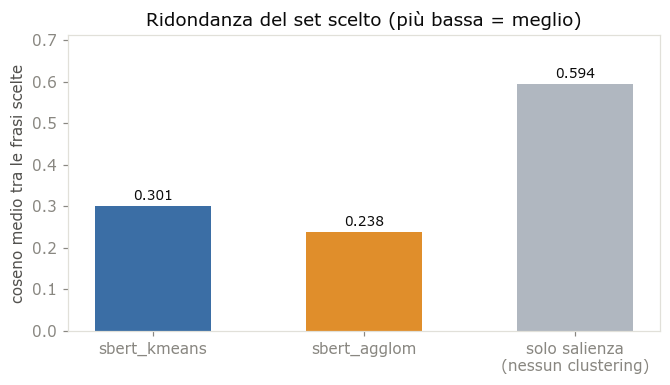

In [21]:
risultati = {}
for var in ALGORITMI:
    sel_ = (ORDINI[var]['frasi'] if N > N_SENTENCES else list(range(N))) if MODALITA == 'frasi' \
        else su.seleziona_per_budget(frasi, ORDINI[var]['budget'], budget)
    testo_ = ' '.join(frasi[i] for i in sorted(sel_))
    if MODALITA == 'budget':
        testo_ = su.tronca_parole(testo_, tetto)
    assert testo_ == (make_genera(var)(documento) if MODALITA == 'frasi' else su.tronca_parole(make_genera(var)(documento, budget=budget), tetto))
    risultati[var] = {'sel': sorted(sel_), 'testo': testo_, 'metriche': su.metriche_esempio(valutatore, testo_, riferimento)}

centro_globale = E.mean(axis=0); centro_globale /= np.linalg.norm(centro_globale)
ordine_salienza = [int(i) for i in np.argsort(-(E @ centro_globale))]
n_sal = len(risultati['sbert_kmeans']['sel'])
sel_sal = sorted(ordine_salienza[:n_sal]) if MODALITA == 'frasi' else sorted(su.seleziona_per_budget(frasi, ordine_salienza, budget))
testo_sal = ' '.join(frasi[i] for i in sel_sal)
testo_sal = testo_sal if MODALITA == 'frasi' else su.tronca_parole(testo_sal, tetto)
risultati['solo salienza'] = {'sel': sel_sal, 'testo': testo_sal, 'metriche': su.metriche_esempio(valutatore, testo_sal, riferimento)}

a, b = risultati['sbert_kmeans'], risultati['sbert_agglom']
print(f"MODALITA '{MODALITA}' | scelte da entrambe: {sorted(set(a['sel']) & set(b['sel']))} | solo kmeans: "
      f"{sorted(set(a['sel']) - set(b['sel']))} | solo agglom: {sorted(set(b['sel']) - set(a['sel']))}")

chiavi = ('rouge1_f1', 'rouge1_p', 'rouge1_r', 'rouge2_f1', 'rougeL_f1', 'meteor', 'parole_generate')
tab = pd.DataFrame({v: {k_: risultati[v]['metriche'][k_] for k_ in chiavi} for v in risultati}).round(3)
tab.loc['frasi scelte'] = [len(risultati[v]['sel']) for v in risultati]
tab.loc['ridondanza (coseno SBERT medio)'] = [round(ridondanza_media(risultati[v]['sel']), 3) for v in risultati]
display(tab)

fig, ax = plt.subplots(figsize=(6.2, 3.6))
valori = [ridondanza_media(risultati[v]['sel']) for v in risultati]
ax.bar(range(3), valori, color=['#3b6ea5', '#e08e2b', '#b0b7c0'], width=.55)
for i_, v in enumerate(valori):
    ax.annotate(f'{v:.3f}', (i_, v), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=9)
ax.set_xticks(range(3)); ax.set_xticklabels(['sbert_kmeans', 'sbert_agglom', 'solo salienza\n(nessun clustering)'])
ax.set_ylabel('coseno medio tra le frasi scelte'); ax.set_title('Ridondanza del set scelto (più bassa = meglio)')
ax.margins(y=.2); plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** La selezione "solo salienza" prende frasi tutte vicine al centro del cluster, quindi
**simili tra loro**: la sua ridondanza è la più alta. Il clustering la abbassa per costruzione. Ma bassa
ridondanza non vuol dire buon riassunto: un singoletto è poco ridondante proprio perché non somiglia a
nulla, e la sua presenza abbassa la ridondanza *e* spesso le metriche.

Su una riga sola i numeri possono andare in qualunque direzione: sulla 50492 a budget vince addirittura
l'agglomerativo, perché i medoidi dei suoi due gruppi più grandi ({0, 3, 11, 14, 16, 17} e {8, 10, 12}) sono
le frasi 11 e 10, entrambe sulla pagina dell'evento Facebook, il cuore del riferimento; K-means, con gruppi
diversi, prende la 0 (il preambolo "UPDATE: …") e la 8. Ecco quelli del benchmark (5.610 righe di
test), letti dai file di `results/metrics/`, con `centroid_mmr_bert` (stesso encoder) come termine di paragone.

In [22]:
import json

righe = []
for v in ('sbert_kmeans', 'sbert_agglom', 'centroid_mmr_bert'):
    for ambito in ('test', 'test_budgetref'):
        percorso = P['metrics_dir'] / f'{v}_{ambito}_aggregate.json'
        if percorso.exists():
            agg = json.loads(percorso.read_text(encoding='utf-8'))
            o = agg['overall']
            righe.append({'metodo': v, 'ambito': ambito, 'righe': agg['n_esempi'],
                          'parole': round(o['parole_generate']), 'ROUGE-1 F1': round(o['rouge1_f1'], 3),
                          'ROUGE-1 P': round(o['rouge1_p'], 3), 'ROUGE-1 R': round(o['rouge1_r'], 3),
                          'ROUGE-2 F1': round(o['rouge2_f1'], 3),
                          'BERTScore F1': round(o['bertscore_f1'], 3) if 'bertscore_f1' in o else None})
if righe:
    display(pd.DataFrame(righe).set_index(['metodo', 'ambito']))
else:
    print('File delle metriche non disponibili (serve results/metrics/ del repository): sezione saltata.')

righe  parole  ROUGE-1 F1  ROUGE-1 P  ROUGE-1 R  ROUGE-2 F1  BERTScore F1
metodo            ambito                                                                                   
sbert_kmeans      test             5588     264       0.359      0.337      0.404       0.125         0.840
                  test_budgetref   5588     215       0.359      0.363      0.358       0.122         0.843
sbert_agglom      test             5588     216       0.328      0.328      0.350       0.106         0.833
                  test_budgetref   5588     215       0.339      0.339      0.342       0.111         0.837
centroid_mmr_bert test             5588     361       0.373      0.326      0.460       0.138         0.841
                  test_budgetref   5588     215       0.364      0.375      0.357       0.127         0.846

**Cosa abbiamo visto.** Nel benchmark K-means batte l'agglomerativo in entrambi gli ambiti, e il divario è
coerente con quanto visto qui: l'agglomerativo spreca più posti in singoletti corti (a 11 frasi produce
riassunti di ~216 parole contro ~264, segno che pesca frasi brevi). A budget il divario si riduce (0,359 vs
0,339) perché l'ordine a giri mette i gruppi grandi davanti e taglia proprio i singoletti. Il confronto con
`centroid_mmr_bert` — stesso encoder, stessa segmentazione — isola la scelta di design: classificare per
salienza globale e correggere la ridondanza (MMR) funziona meglio, su Multi-News, che partizionare e dare un
posto a ogni gruppo.